# DSCI 552 – Homework 5

**Name:** Nishtha Joshi
**USC ID** : 4515720287


## 1. Decision Trees as Interpretable Models

This section uses the Acute Inflammations dataset from the UCI Machine
Learning Repository. The dataset contains six predictor variables and two
diagnosis variables.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
from math import sqrt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree,
    _tree
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)
from sklearn.metrics import accuracy_score

sns.set_theme(style="whitegrid")

seed_value = 42

### 1(a) Downloading and Preparing the Dataset

The Acute Inflammations dataset was downloaded from the UCI Machine Learning
Repository. It contains 120 observations, six symptom variables, and two
diagnosis variables. The temperature values were converted to numeric form,
and the Yes and No values were represented using 1 and 0.

In [2]:
notebook_location = Path.cwd()

if notebook_location.name == "notebook":
    homework_root = notebook_location.parent
else:
    homework_root = notebook_location

dataset_root = homework_root / "data"
inflammation_folder = dataset_root / "acute_inflammations"

dataset_root.mkdir(parents=True, exist_ok=True)
inflammation_folder.mkdir(parents=True, exist_ok=True)

print("Homework folder:", homework_root)
print("Dataset folder:", dataset_root)

Homework folder: /Users/nishtha/Desktop/DSCI-552-HW-5
Dataset folder: /Users/nishtha/Desktop/DSCI-552-HW-5/data


In [3]:
inflammation_url = (
    "https://archive.ics.uci.edu/static/public/184/"
    "acute%2Binflammations.zip"
)

downloaded_archive = (
    inflammation_folder / "acute_inflammations.zip"
)

if not downloaded_archive.exists():
    urlretrieve(
        inflammation_url,
        downloaded_archive
    )
    print("Dataset downloaded.")
else:
    print("The ZIP file is already available.")

diagnosis_files = list(
    inflammation_folder.rglob("diagnosis.data")
)

if not diagnosis_files:
    with ZipFile(downloaded_archive, "r") as archive_reader:
        archive_reader.extractall(inflammation_folder)

    print("Dataset extracted.")

    diagnosis_files = list(
        inflammation_folder.rglob("diagnosis.data")
    )
else:
    print("The dataset has already been extracted.")

diagnosis_source = diagnosis_files[0]

print("Dataset file:", diagnosis_source)

The ZIP file is already available.
The dataset has already been extracted.
Dataset file: /Users/nishtha/Desktop/DSCI-552-HW-5/data/acute_inflammations/diagnosis.data


In [4]:
record_fields = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "burning_urethra",
    "bladder_inflammation",
    "nephritis"
]


def read_inflammation_records(source_file):
    encoding_choices = [
        "utf-16",
        "utf-8-sig",
        "latin1"
    ]

    for text_encoding in encoding_choices:
        try:
            candidate_records = pd.read_csv(
                source_file,
                sep=r"\s+",
                header=None,
                names=record_fields,
                encoding=text_encoding,
                dtype=str,
                engine="python"
            )

            if (
                candidate_records.shape[1]
                == len(record_fields)
                and not candidate_records.empty
            ):
                return candidate_records

        except (UnicodeError, pd.errors.ParserError):
            continue

    raise ValueError(
        "The Acute Inflammations file could not be read."
    )


inflammation_records = read_inflammation_records(
    diagnosis_source
)

inflammation_records.head()

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,burning_urethra,bladder_inflammation,nephritis
0,"35,5",no,yes,no,no,no,no,no
1,"35,9",no,no,yes,yes,yes,yes,no
2,"35,9",no,yes,no,no,no,no,no
3,"36,0",no,no,yes,yes,yes,yes,no
4,"36,0",no,yes,no,no,no,no,no


In [5]:
inflammation_records["temperature"] = (
    inflammation_records["temperature"]
    .str.strip()
    .str.replace(",", ".", regex=False)
    .astype(float)
)

binary_fields = record_fields[1:]

for field_name in binary_fields:
    inflammation_records[field_name] = (
        inflammation_records[field_name]
        .str.strip()
        .str.lower()
        .map({
            "yes": 1,
            "no": 0
        })
    )

print(
    "Dataset shape:",
    inflammation_records.shape
)

print("\nMissing values:")
print(inflammation_records.isna().sum())

inflammation_records.head()

Dataset shape: (120, 8)

Missing values:
temperature             0
nausea                  0
lumbar_pain             0
urine_pushing           0
micturition_pain        0
burning_urethra         0
bladder_inflammation    0
nephritis               0
dtype: int64


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,burning_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


In [6]:
diagnosis_counts = (
    inflammation_records[
        [
            "bladder_inflammation",
            "nephritis"
        ]
    ]
    .value_counts()
    .rename("number_of_cases")
    .reset_index()
)

diagnosis_counts

,bladder_inflammation,nephritis,number_of_cases
0,1,0,40
1,0,1,31
2,0,0,30
3,1,1,19


### 1(b) Full Decision Tree

The dataset has two diagnosis labels. I used the label powerset method to
combine them into one response with four possible diagnosis combinations.

This method is useful here because the two diagnoses may be related. Binary
relevance would fit a separate tree for each diagnosis and would not directly
consider that relationship. Label powerset is also manageable because there
are only two labels and four possible combinations.

The decision tree was fitted using the complete dataset, as required.

In [7]:
symptom_fields = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "burning_urethra"
]

symptom_matrix = inflammation_records[
    symptom_fields
].copy()

diagnosis_pattern = (
    inflammation_records["bladder_inflammation"] * 2
    + inflammation_records["nephritis"]
)

diagnosis_key = {
    0: "Bladder: No, Nephritis: No",
    1: "Bladder: No, Nephritis: Yes",
    2: "Bladder: Yes, Nephritis: No",
    3: "Bladder: Yes, Nephritis: Yes"
}

pattern_counts = (
    diagnosis_pattern
    .map(diagnosis_key)
    .value_counts()
    .rename("number_of_cases")
)

pattern_counts

Bladder: Yes, Nephritis: No     40
Bladder: No, Nephritis: Yes     31
Bladder: No, Nephritis: No      30
Bladder: Yes, Nephritis: Yes    19
Name: number_of_cases, dtype: int64

In [8]:
baseline_tree = DecisionTreeClassifier(
    random_state=seed_value
)

baseline_tree.fit(
    symptom_matrix,
    diagnosis_pattern
)

baseline_guesses = baseline_tree.predict(
    symptom_matrix
)

baseline_training_score = accuracy_score(
    diagnosis_pattern,
    baseline_guesses
)

print(
    "Full-tree training accuracy:",
    f"{baseline_training_score:.4f}"
)

print(
    "Tree depth:",
    baseline_tree.get_depth()
)

print(
    "Number of leaves:",
    baseline_tree.get_n_leaves()
)

print(
    "Number of nodes:",
    baseline_tree.tree_.node_count
)

Full-tree training accuracy: 1.0000
Tree depth: 4
Number of leaves: 6
Number of nodes: 11


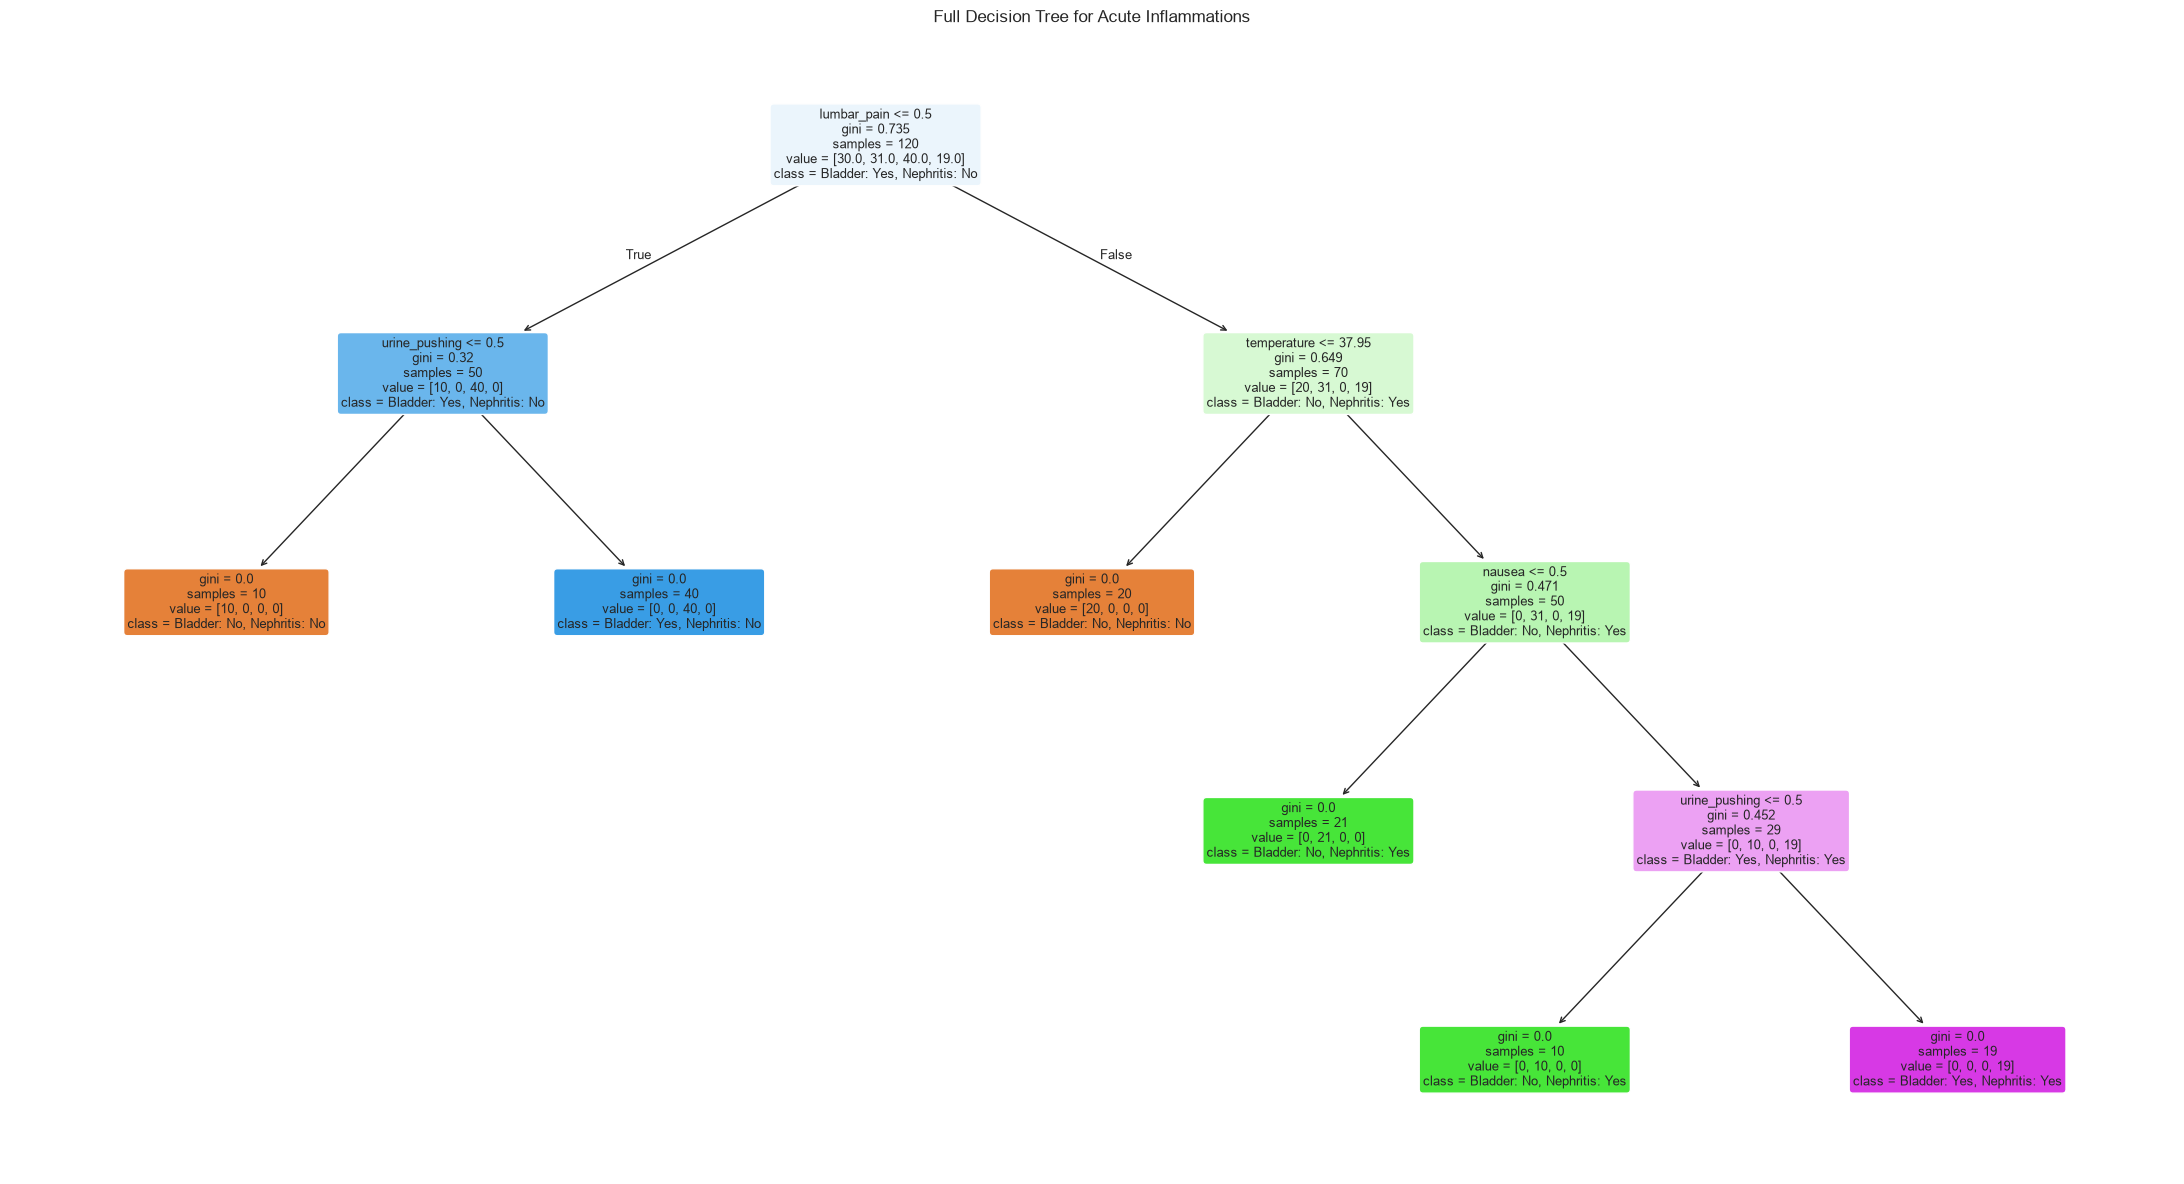

In [9]:
baseline_class_names = [
    diagnosis_key[class_code]
    for class_code in baseline_tree.classes_
]

plt.figure(figsize=(22, 12))

plot_tree(
    baseline_tree,
    feature_names=symptom_fields,
    class_names=baseline_class_names,
    filled=True,
    rounded=True,
    proportion=False,
    fontsize=9
)

plt.title(
    "Full Decision Tree for Acute Inflammations"
)
plt.tight_layout()
plt.show()

### 1(c) IF-THEN Rules

Each path from the root of the tree to a terminal leaf was converted into an
IF-THEN rule. The conditions describe the symptom values, and the result of
each rule gives the predicted combination of bladder inflammation and
nephritis.

In [10]:
def describe_branch(
    feature_name,
    threshold_value,
    follows_left
):
    if feature_name == "temperature":
        comparison = "<=" if follows_left else ">"

        return (
            f"temperature {comparison} "
            f"{threshold_value:.2f}"
        )

    symptom_value = "No" if follows_left else "Yes"

    return f"{feature_name} = {symptom_value}"


def extract_rule_paths(
    fitted_model,
    feature_names,
    label_dictionary
):
    tree_structure = fitted_model.tree_
    rule_paths = []

    def follow_node(node_id, earlier_conditions):
        field_position = tree_structure.feature[node_id]

        if field_position != _tree.TREE_UNDEFINED:
            feature_name = feature_names[field_position]
            threshold_value = tree_structure.threshold[node_id]

            left_statement = describe_branch(
                feature_name,
                threshold_value,
                True
            )

            follow_node(
                tree_structure.children_left[node_id],
                earlier_conditions + [left_statement]
            )

            right_statement = describe_branch(
                feature_name,
                threshold_value,
                False
            )

            follow_node(
                tree_structure.children_right[node_id],
                earlier_conditions + [right_statement]
            )

        else:
            predicted_position = np.argmax(
                tree_structure.value[node_id][0]
            )

            predicted_code = (
                fitted_model.classes_[predicted_position]
            )

            predicted_diagnosis = label_dictionary[
                predicted_code
            ]

            cases_in_leaf = (
                tree_structure.n_node_samples[node_id]
            )

            if earlier_conditions:
                combined_conditions = " AND ".join(
                    earlier_conditions
                )
            else:
                combined_conditions = "Always"

            current_rule = (
                f"IF {combined_conditions}\n"
                f"THEN {predicted_diagnosis} "
                f"(observations = {cases_in_leaf})"
            )

            rule_paths.append(current_rule)

    follow_node(0, [])

    return rule_paths

In [11]:
baseline_rule_paths = extract_rule_paths(
    baseline_tree,
    symptom_fields,
    diagnosis_key
)

for rule_number, rule_text in enumerate(
    baseline_rule_paths,
    start=1
):
    print(f"Rule {rule_number}")
    print(rule_text)
    print("-" * 70)

Rule 1
IF lumbar_pain = No AND urine_pushing = No
THEN Bladder: No, Nephritis: No (observations = 10)
----------------------------------------------------------------------
Rule 2
IF lumbar_pain = No AND urine_pushing = Yes
THEN Bladder: Yes, Nephritis: No (observations = 40)
----------------------------------------------------------------------
Rule 3
IF lumbar_pain = Yes AND temperature <= 37.95
THEN Bladder: No, Nephritis: No (observations = 20)
----------------------------------------------------------------------
Rule 4
IF lumbar_pain = Yes AND temperature > 37.95 AND nausea = No
THEN Bladder: No, Nephritis: Yes (observations = 21)
----------------------------------------------------------------------
Rule 5
IF lumbar_pain = Yes AND temperature > 37.95 AND nausea = Yes AND urine_pushing = No
THEN Bladder: No, Nephritis: Yes (observations = 10)
----------------------------------------------------------------------
Rule 6
IF lumbar_pain = Yes AND temperature > 37.95 AND nausea = Yes

#### Interpretation of the Full-Tree Rules

The first split is based on lumbar pain. For patients without lumbar pain,
urine pushing determines whether bladder inflammation is predicted. When
lumbar pain is present, temperature becomes important. Patients with a
temperature at or below 37.95 are classified as having neither condition.

For patients with lumbar pain and a temperature above 37.95, the tree mainly
predicts nephritis. Nausea and urine pushing are then used to distinguish the
cases where both bladder inflammation and nephritis are present. Overall, the
rules are fairly short and easy to interpret.

### 1(d) Cost-Complexity Pruning

The full decision tree classifies the training observations correctly, but a
smaller tree may be easier to interpret. I used cost-complexity pruning with
five-fold stratified cross-validation. The one-standard-error rule was used
to select the smallest tree whose validation accuracy remained close to the
best result.

In [12]:
complexity_path = (
    baseline_tree.cost_complexity_pruning_path(
        symptom_matrix,
        diagnosis_pattern
    )
)

pruning_levels = np.unique(
    complexity_path.ccp_alphas
)

print(
    "Number of candidate alpha values:",
    len(pruning_levels)
)

Number of candidate alpha values: 5


In [13]:
stratified_splits = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=seed_value
)

pruning_checks = []

for penalty_value in pruning_levels:
    candidate_tree = DecisionTreeClassifier(
        random_state=seed_value,
        ccp_alpha=penalty_value
    )

    validation_scores = cross_val_score(
        candidate_tree,
        symptom_matrix,
        diagnosis_pattern,
        cv=stratified_splits,
        scoring="accuracy"
    )

    candidate_tree.fit(
        symptom_matrix,
        diagnosis_pattern
    )

    score_deviation = validation_scores.std(ddof=1)

    pruning_checks.append({
        "ccp_alpha": penalty_value,
        "mean_cv_accuracy": validation_scores.mean(),
        "std_cv_accuracy": score_deviation,
        "standard_error": (
            score_deviation
            / np.sqrt(
                stratified_splits.get_n_splits()
            )
        ),
        "tree_depth": candidate_tree.get_depth(),
        "number_of_leaves": (
            candidate_tree.get_n_leaves()
        ),
        "number_of_nodes": (
            candidate_tree.tree_.node_count
        )
    })

pruning_table = pd.DataFrame(pruning_checks)

pruning_table.round(4)

,ccp_alpha,mean_cv_accuracy,std_cv_accuracy,standard_error,tree_depth,number_of_leaves,number_of_nodes
0,0.0000,0.9917,0.0186,0.0083,4,6,11
1,0.0982,0.8583,0.0559,0.0250,2,4,7
2,0.1333,0.7583,0.0745,0.0333,2,3,5
3,0.1820,0.6667,0.0659,0.0295,1,2,3
4,0.2229,0.4833,0.1369,0.0612,0,1,1


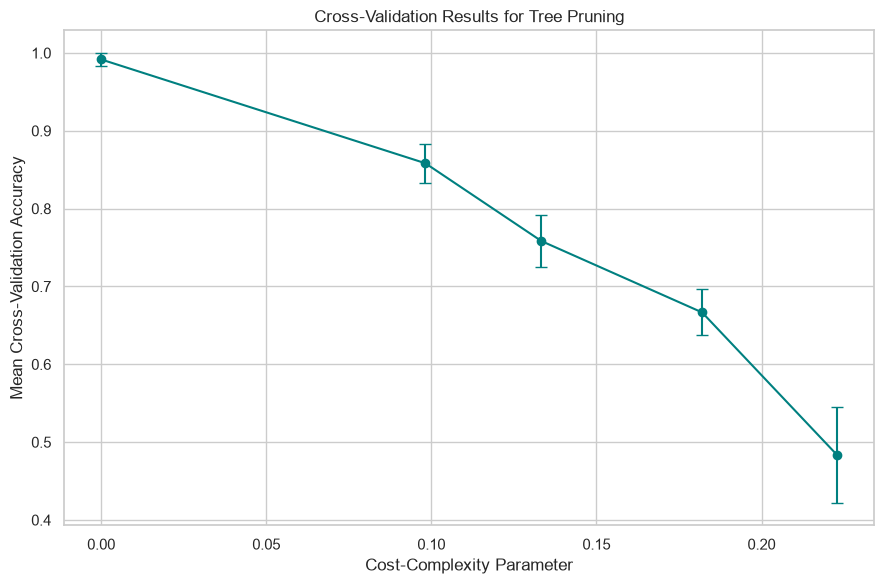

In [14]:
plt.figure(figsize=(9, 6))

plt.errorbar(
    pruning_table["ccp_alpha"],
    pruning_table["mean_cv_accuracy"],
    yerr=pruning_table["standard_error"],
    marker="o",
    capsize=4,
    color="teal"
)

plt.xlabel("Cost-Complexity Parameter")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.title("Cross-Validation Results for Tree Pruning")
plt.tight_layout()
plt.show()

In [15]:
highest_score_row = (
    pruning_table["mean_cv_accuracy"].idxmax()
)

highest_mean_score = pruning_table.loc[
    highest_score_row,
    "mean_cv_accuracy"
]

highest_score_error = pruning_table.loc[
    highest_score_row,
    "standard_error"
]

one_se_boundary = (
    highest_mean_score - highest_score_error
)

eligible_pruning_rows = pruning_table[
    pruning_table["mean_cv_accuracy"]
    >= one_se_boundary
].copy()

selected_pruning_row = (
    eligible_pruning_rows
    .sort_values(
        by=["number_of_leaves", "ccp_alpha"],
        ascending=[True, False]
    )
    .iloc[0]
)

selected_penalty = selected_pruning_row[
    "ccp_alpha"
]

print(
    f"Highest mean CV accuracy: "
    f"{highest_mean_score:.4f}"
)

print(
    f"One-SE accuracy boundary: "
    f"{one_se_boundary:.4f}"
)

print(
    f"Selected ccp_alpha: "
    f"{selected_penalty:.6f}"
)

print(
    "Selected number of leaves:",
    int(
        selected_pruning_row[
            "number_of_leaves"
        ]
    )
)

Highest mean CV accuracy: 0.9917
One-SE accuracy boundary: 0.9833
Selected ccp_alpha: 0.000000
Selected number of leaves: 6


In [16]:
selected_tree = DecisionTreeClassifier(
    random_state=seed_value,
    ccp_alpha=selected_penalty
)

selected_tree.fit(
    symptom_matrix,
    diagnosis_pattern
)

selected_guesses = selected_tree.predict(
    symptom_matrix
)

selected_training_score = accuracy_score(
    diagnosis_pattern,
    selected_guesses
)

selected_fold_scores = cross_val_score(
    DecisionTreeClassifier(
        random_state=seed_value,
        ccp_alpha=selected_penalty
    ),
    symptom_matrix,
    diagnosis_pattern,
    cv=stratified_splits,
    scoring="accuracy"
)

baseline_fold_scores = cross_val_score(
    DecisionTreeClassifier(
        random_state=seed_value,
        ccp_alpha=0
    ),
    symptom_matrix,
    diagnosis_pattern,
    cv=stratified_splits,
    scoring="accuracy"
)

model_summary = pd.DataFrame({
    "tree_version": [
        "Original tree",
        "Tree selected by pruning"
    ],
    "ccp_alpha": [
        0.0,
        selected_penalty
    ],
    "nodes": [
        baseline_tree.tree_.node_count,
        selected_tree.tree_.node_count
    ],
    "leaves": [
        baseline_tree.get_n_leaves(),
        selected_tree.get_n_leaves()
    ],
    "depth": [
        baseline_tree.get_depth(),
        selected_tree.get_depth()
    ],
    "training_accuracy": [
        baseline_training_score,
        selected_training_score
    ],
    "mean_cv_accuracy": [
        baseline_fold_scores.mean(),
        selected_fold_scores.mean()
    ]
})

model_summary.round(4)

,tree_version,ccp_alpha,nodes,leaves,depth,training_accuracy,mean_cv_accuracy
0,Original tree,0.0,11,6,4,1.0,0.9917
1,Tree selected by pruning,0.0,11,6,4,1.0,0.9917


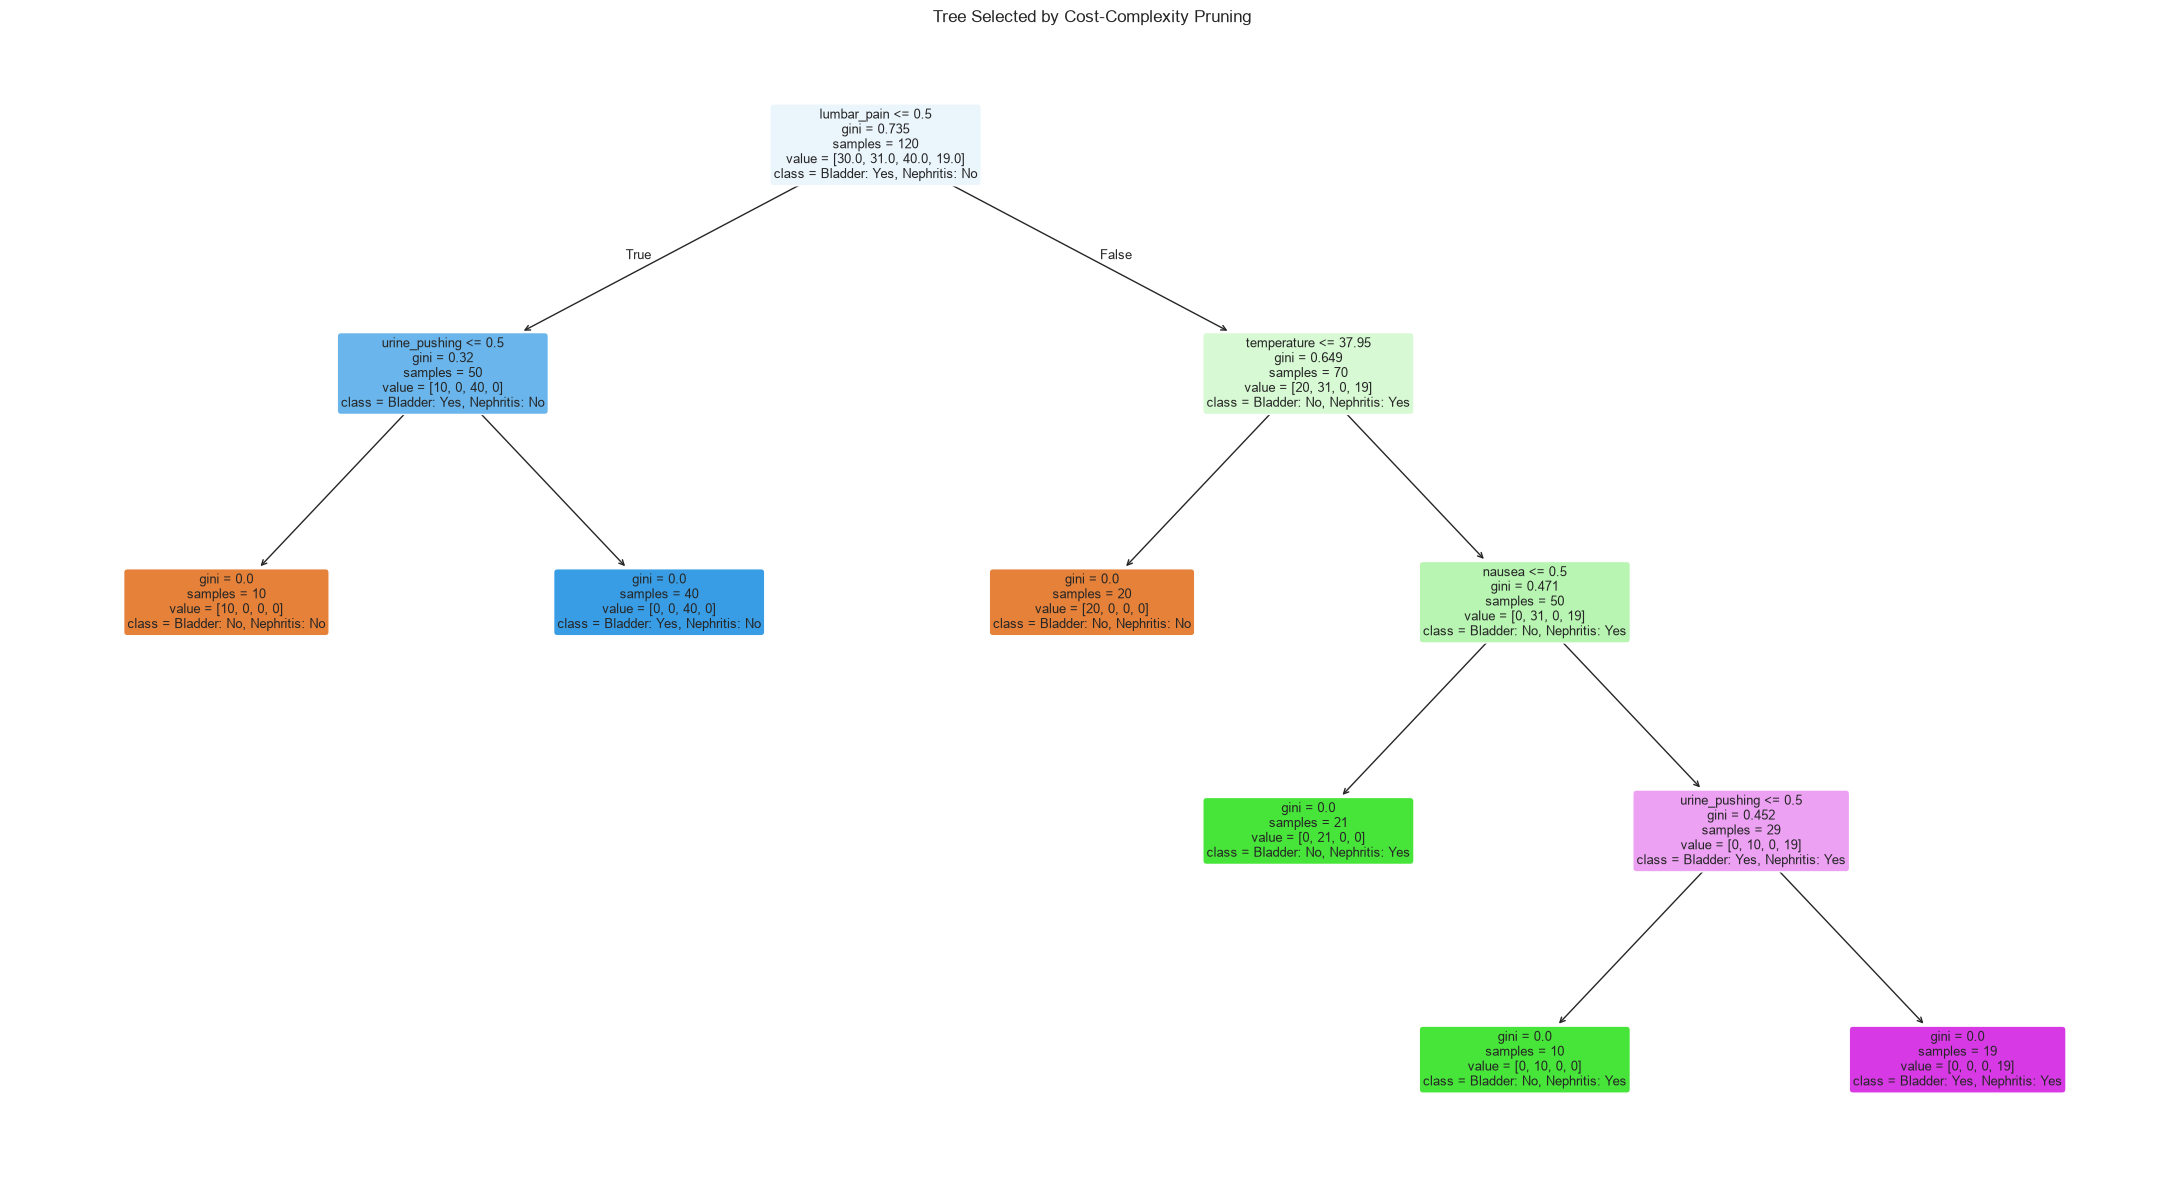

In [17]:
selected_class_names = [
    diagnosis_key[class_code]
    for class_code in selected_tree.classes_
]

plt.figure(figsize=(22, 12))

plot_tree(
    selected_tree,
    feature_names=symptom_fields,
    class_names=selected_class_names,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title(
    "Tree Selected by Cost-Complexity Pruning"
)

plt.tight_layout()
plt.show()

In [18]:
selected_rule_paths = extract_rule_paths(
    selected_tree,
    symptom_fields,
    diagnosis_key
)

for rule_number, rule_text in enumerate(
    selected_rule_paths,
    start=1
):
    print(f"Rule {rule_number}")
    print(rule_text)
    print("-" * 70)

Rule 1
IF lumbar_pain = No AND urine_pushing = No
THEN Bladder: No, Nephritis: No (observations = 10)
----------------------------------------------------------------------
Rule 2
IF lumbar_pain = No AND urine_pushing = Yes
THEN Bladder: Yes, Nephritis: No (observations = 40)
----------------------------------------------------------------------
Rule 3
IF lumbar_pain = Yes AND temperature <= 37.95
THEN Bladder: No, Nephritis: No (observations = 20)
----------------------------------------------------------------------
Rule 4
IF lumbar_pain = Yes AND temperature > 37.95 AND nausea = No
THEN Bladder: No, Nephritis: Yes (observations = 21)
----------------------------------------------------------------------
Rule 5
IF lumbar_pain = Yes AND temperature > 37.95 AND nausea = Yes AND urine_pushing = No
THEN Bladder: No, Nephritis: Yes (observations = 10)
----------------------------------------------------------------------
Rule 6
IF lumbar_pain = Yes AND temperature > 37.95 AND nausea = Yes

#### Pruning Result

The unpruned tree had 11 nodes, 6 terminal leaves, and a depth of 4. Its
mean five-fold cross-validation accuracy was 0.9917.

The one-standard-error boundary was 0.9833. The first genuinely smaller tree
had 4 leaves, but its mean cross-validation accuracy decreased to 0.8583.
Therefore, none of the smaller trees satisfied the one-standard-error rule.

The selected cost-complexity parameter was consequently zero. This means
that cost-complexity pruning did not remove any branches. Although the
selected tree is the same as the original tree, it is already relatively
small, with only six terminal rules. Further pruning would make the tree
simpler, but it would cause a considerable reduction in classification
accuracy. Therefore, the original six-leaf tree was retained as the final
interpretable model.

## 2. LASSO and Boosting for Regression

The Communities and Crime dataset is used to predict the violent crime rate
of a community. According to the assignment, the first 1,495 observations
are used as the training set and the remaining observations are used as the
test set. The order of the observations is therefore preserved during the
split.

In [19]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)
from sklearn.decomposition import PCA
from sklearn.model_selection import (
    KFold,
    GridSearchCV
)
from sklearn.metrics import mean_squared_error

### 2(a) Downloading and Splitting the Dataset

The dataset and its attribute-description file are downloaded from the UCI
Machine Learning Repository. The attribute names are read directly from the
description file instead of being manually entered.

In [20]:
crime_folder = (
    dataset_root / "communities_and_crime"
)

crime_folder.mkdir(
    parents=True,
    exist_ok=True
)

crime_data_url = (
    "https://archive.ics.uci.edu/static/public/183/"
    "communities%2Band%2Bcrime.zip"
)

crime_archive = (
    crime_folder / "communities_and_crime.zip"
)

if not crime_archive.exists():
    urlretrieve(
        crime_data_url,
        crime_archive
    )
    print("Communities and Crime dataset downloaded.")
else:
    print("The ZIP file is already available.")

crime_data_files = list(
    crime_folder.rglob("communities.data")
)

if not crime_data_files:
    with ZipFile(crime_archive, "r") as archive_reader:
        archive_reader.extractall(crime_folder)

    print("Dataset extracted.")
else:
    print("The dataset has already been extracted.")

crime_data_files = list(
    crime_folder.rglob("communities.data")
)

crime_name_files = list(
    crime_folder.rglob("communities.names")
)

crime_source = crime_data_files[0]
attribute_source = crime_name_files[0]

print("Data file:", crime_source)
print("Attribute file:", attribute_source)

The ZIP file is already available.
The dataset has already been extracted.
Data file: /Users/nishtha/Desktop/DSCI-552-HW-5/data/communities_and_crime/communities.data
Attribute file: /Users/nishtha/Desktop/DSCI-552-HW-5/data/communities_and_crime/communities.names


In [21]:
crime_fields = []

with open(
    attribute_source,
    "r",
    encoding="latin1"
) as attribute_reader:

    for description_line in attribute_reader:
        cleaned_line = description_line.strip()

        if cleaned_line.lower().startswith("@attribute"):
            line_parts = cleaned_line.split()

            field_name = (
                line_parts[1]
                .strip("'")
                .strip('"')
            )

            crime_fields.append(field_name)

print(
    "Number of columns found:",
    len(crime_fields)
)

print("\nFirst ten columns:")
print(crime_fields[:10])

print("\nLast column:")
print(crime_fields[-1])

Number of columns found: 128

First ten columns:
['state', 'county', 'community', 'communityname', 'fold', 'population', 'householdsize', 'racepctblack', 'racePctWhite', 'racePctAsian']

Last column:
ViolentCrimesPerPop


In [22]:
community_records = pd.read_csv(
    crime_source,
    header=None,
    names=crime_fields,
    na_values="?"
)

print(
    "Complete dataset shape:",
    community_records.shape
)

community_records.head()

Complete dataset shape: (1994, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [23]:
nonpredictive_fields = [
    "state",
    "county",
    "community",
    "communityname",
    "fold"
]

response_field = "ViolentCrimesPerPop"

usable_fields = [
    field_name
    for field_name in community_records.columns
    if field_name not in (
        nonpredictive_fields + [response_field]
    )
]

community_predictors = community_records[
    usable_fields
].apply(
    pd.to_numeric,
    errors="coerce"
)

crime_response = pd.to_numeric(
    community_records[response_field],
    errors="coerce"
)

print(
    "Number of predictive features:",
    len(usable_fields)
)

print(
    "Predictor matrix shape:",
    community_predictors.shape
)

Number of predictive features: 122
Predictor matrix shape: (1994, 122)


In [24]:
training_limit = 1495

crime_train_x = (
    community_predictors
    .iloc[:training_limit]
    .copy()
)

crime_test_x = (
    community_predictors
    .iloc[training_limit:]
    .copy()
)

crime_train_y = (
    crime_response
    .iloc[:training_limit]
    .copy()
)

crime_test_y = (
    crime_response
    .iloc[training_limit:]
    .copy()
)

split_summary = pd.DataFrame({
    "portion": [
        "Training",
        "Test"
    ],
    "observations": [
        len(crime_train_x),
        len(crime_test_x)
    ],
    "predictive_features": [
        crime_train_x.shape[1],
        crime_test_x.shape[1]
    ]
})

split_summary

,portion,observations,predictive_features
0,Training,1495,122
1,Test,499,122


The columns state, county, community, community name, and fold were removed
because they are not predictive features. After removing them, the dataset
contained 122 predictors.

The first 1,495 rows were used for training. The remaining 499 rows were used
for testing, as required in the question.

### 2(b) Missing Values

Some of the predictors contain missing values. I used median imputation
because the median is less affected by unusually large or small values.

The imputer was fitted using only the training data. The same fitted imputer
was then used to transform the test data. This keeps information from the
test set out of the training process.

In [25]:
missing_report = pd.DataFrame({
    "training_missing": (
        crime_train_x.isna().sum()
    ),
    "test_missing": (
        crime_test_x.isna().sum()
    )
})

missing_report = (
    missing_report[
        missing_report.sum(axis=1) > 0
    ]
    .sort_values(
        by="training_missing",
        ascending=False
    )
)

print(
    "Features with missing values:",
    len(missing_report)
)

print(
    "Total missing values in training data:",
    int(crime_train_x.isna().sum().sum())
)

print(
    "Total missing values in test data:",
    int(crime_test_x.isna().sum().sum())
)

missing_report

Features with missing values: 23
Total missing values in training data: 27633
Total missing values in test data: 9218


,training_missing,test_missing
PctPolicBlack,1256,419
PctPolicHisp,1256,419
LemasGangUnitDeploy,1256,419
LemasPctPolicOnPatr,1256,419
PolicOperBudg,1256,419
PolicCars,1256,419
PolicAveOTWorked,1256,419
NumKindsDrugsSeiz,1256,419
OfficAssgnDrugUnits,1256,419
PctPolicMinor,1256,419


In [26]:
crime_imputer = SimpleImputer(
    strategy="median"
)

crime_train_filled = pd.DataFrame(
    crime_imputer.fit_transform(crime_train_x),
    columns=usable_fields,
    index=crime_train_x.index
)

crime_test_filled = pd.DataFrame(
    crime_imputer.transform(crime_test_x),
    columns=usable_fields,
    index=crime_test_x.index
)

print(
    "Missing values after training imputation:",
    int(crime_train_filled.isna().sum().sum())
)

print(
    "Missing values after test imputation:",
    int(crime_test_filled.isna().sum().sum())
)

print(
    "Training shape:",
    crime_train_filled.shape
)

print(
    "Test shape:",
    crime_test_filled.shape
)

Missing values after training imputation: 0
Missing values after test imputation: 0
Training shape: (1495, 122)
Test shape: (499, 122)


In [27]:
print(
    "Missing training responses:",
    int(crime_train_y.isna().sum())
)

print(
    "Missing test responses:",
    int(crime_test_y.isna().sum())
)

Missing training responses: 0
Missing test responses: 0


The missing predictor values were replaced with the median of each training
feature. After imputation, there were no missing values in either the
training or test predictor set. The response variable did not contain any
missing values.

### 2(c) Correlation Matrix

The correlation matrix was calculated using the imputed training predictors.
It shows the direction and strength of the linear relationship between each
pair of features.

In [28]:
feature_correlations = (
    crime_train_filled.corr()
)

print(
    "Correlation matrix shape:",
    feature_correlations.shape
)

feature_correlations.iloc[:5, :5]

Correlation matrix shape: (122, 122)


,population,householdsize,racepctblack,racePctWhite,racePctAsian
population,1.000000,-0.040404,0.242144,-0.306023,0.168868
householdsize,-0.040404,1.000000,-0.068374,-0.243565,0.209848
racepctblack,0.242144,-0.068374,1.000000,-0.793431,-0.104912
racePctWhite,-0.306023,-0.243565,-0.793431,1.000000,-0.270829
racePctAsian,0.168868,0.209848,-0.104912,-0.270829,1.000000


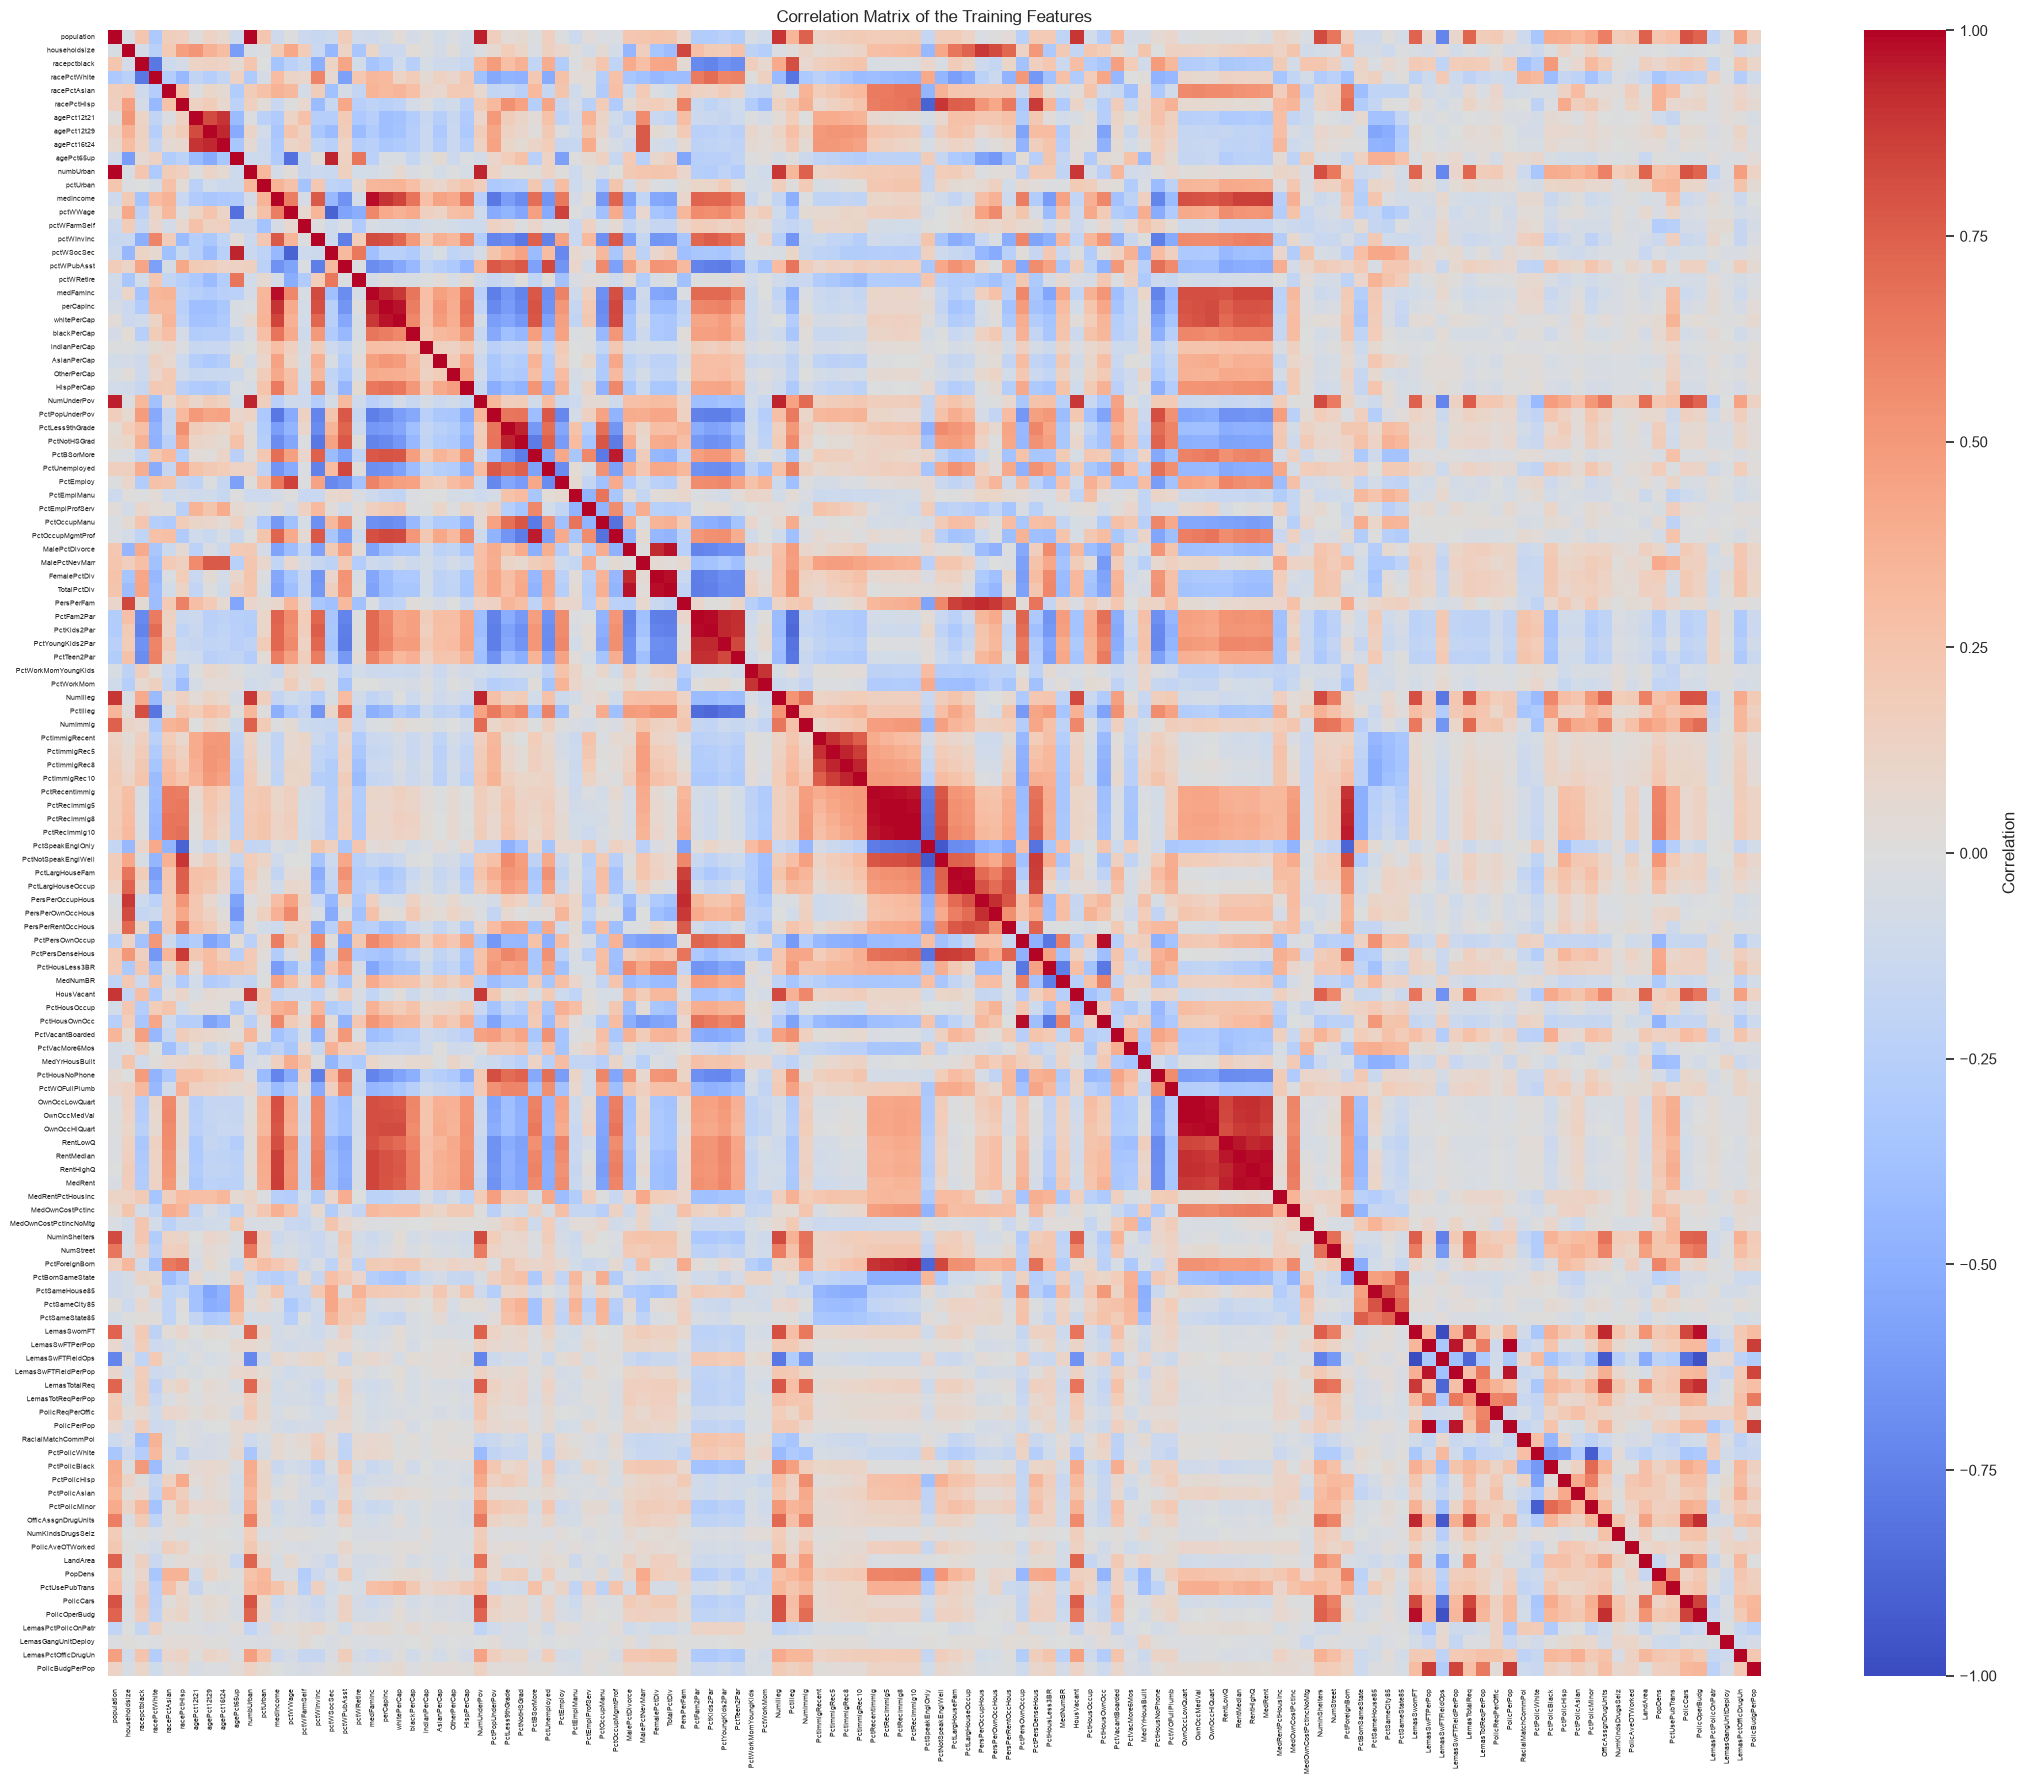

In [29]:
plt.figure(figsize=(22, 18))

sns.heatmap(
    feature_correlations,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={
        "label": "Correlation"
    }
)

plt.title(
    "Correlation Matrix of the Training Features"
)

plt.xticks(
    rotation=90,
    fontsize=5
)

plt.yticks(
    rotation=0,
    fontsize=5
)

plt.tight_layout()
plt.show()

In [30]:
upper_triangle = np.triu(
    np.ones(
        feature_correlations.shape,
        dtype=bool
    ),
    k=1
)

correlation_pairs = (
    feature_correlations
    .where(upper_triangle)
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "first_feature",
    "second_feature",
    "correlation"
]

correlation_pairs["absolute_correlation"] = (
    correlation_pairs["correlation"].abs()
)

strongest_pairs = (
    correlation_pairs
    .sort_values(
        by="absolute_correlation",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

strongest_pairs.round(4)

,first_feature,second_feature,correlation,absolute_correlation
0,LemasSwFTPerPop,PolicPerPop,1.0000,1.0000
1,PctRecImmig8,PctRecImmig10,0.9956,0.9956
2,OwnOccLowQuart,OwnOccMedVal,0.9947,0.9947
3,LemasSwornFT,LemasSwFTFieldOps,-0.9945,0.9945
4,population,numbUrban,0.9936,0.9936
5,PctRecImmig5,PctRecImmig8,0.9927,0.9927
6,OwnOccMedVal,OwnOccHiQuart,0.9916,0.9916
7,PctRecentImmig,PctRecImmig5,0.9894,0.9894
8,RentMedian,MedRent,0.9888,0.9888
9,PctFam2Par,PctKids2Par,0.9856,0.9856


Several predictors have correlations close to 1. For example,
LemasSwFTPerPop and PolicPerPop have a correlation of 1. The immigration
features PctRecImmig8 and PctRecImmig10 have a correlation of 0.9956.
Population and numbUrban are also strongly related, with a correlation of
0.9936.

There is also a strong negative relationship between LemasSwornFT and
LemasSwFTFieldOps, with a correlation of -0.9945. These results show that
the dataset contains considerable correlation between some predictors.
This can make ordinary least squares coefficients less stable.

### 2(d) Coefficient of Variation

The coefficient of variation was calculated for each predictor using

\[
CV = \frac{s}{m}
\]

where \(s\) is the sample standard deviation and \(m\) is the sample mean.
The calculation was performed using the training data.

In [31]:
feature_averages = (
    crime_train_filled.mean()
)

feature_spreads = (
    crime_train_filled.std(ddof=1)
)

safe_averages = feature_averages.replace(
    0,
    np.nan
)

variation_ratio = (
    feature_spreads / safe_averages
)

variation_table = pd.DataFrame({
    "feature": usable_fields,
    "mean": feature_averages.values,
    "sample_standard_deviation": feature_spreads.values,
    "coefficient_of_variation": variation_ratio.values
})

variation_table = (
    variation_table
    .sort_values(
        by="coefficient_of_variation",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "Number of features:",
    len(variation_table)
)

print(
    "Undefined CV values:",
    int(
        variation_table[
            "coefficient_of_variation"
        ].isna().sum()
    )
)

variation_table.head(15).round(4)

Number of features: 122
Undefined CV values: 0


,feature,mean,sample_standard_deviation,coefficient_of_variation
0,PctPolicAsian,0.0163,0.0898,5.5271
1,NumStreet,0.0230,0.0987,4.2929
2,NumInShelters,0.0296,0.1027,3.4710
3,NumIlleg,0.0372,0.1138,3.0590
4,NumImmig,0.0306,0.0895,2.9266
5,LemasPctOfficDrugUn,0.0933,0.2382,2.5529
6,NumUnderPov,0.0568,0.1332,2.3424
7,LemasSwornFT,0.0287,0.0646,2.2480
8,population,0.0582,0.1304,2.2411
9,numbUrban,0.0646,0.1318,2.0385


In [32]:
with pd.option_context(
    "display.max_rows",
    None
):
    display(
        variation_table.round(4)
    )

,feature,mean,sample_standard_deviation,coefficient_of_variation
0,PctPolicAsian,0.0163,0.0898,5.5271
1,NumStreet,0.0230,0.0987,4.2929
2,NumInShelters,0.0296,0.1027,3.4710
3,NumIlleg,0.0372,0.1138,3.0590
4,NumImmig,0.0306,0.0895,2.9266
5,LemasPctOfficDrugUn,0.0933,0.2382,2.5529
6,NumUnderPov,0.0568,0.1332,2.3424
7,LemasSwornFT,0.0287,0.0646,2.2480
8,population,0.0582,0.1304,2.2411
9,numbUrban,0.0646,0.1318,2.0385


A larger coefficient of variation means that the feature has more variation
relative to its mean. Features with high CV values may show larger relative
differences across communities. A high CV does not automatically mean that
a feature is a strong predictor of violent crime.

### 2(e) Features With the Highest Coefficients of Variation

The question asks for \(\lfloor\sqrt{128}\rfloor\), which gives 11 features.
The 11 predictors with the highest coefficients of variation were selected.
Scatterplots were used to compare these features with the response, and
boxplots were used to examine their distributions.

In [33]:
number_selected = int(
    np.floor(np.sqrt(128))
)

high_cv_fields = (
    variation_table
    .head(number_selected)["feature"]
    .tolist()
)

selected_cv_table = (
    variation_table
    .head(number_selected)
    .copy()
)

print(
    "Number of selected features:",
    number_selected
)

selected_cv_table.round(4)

Number of selected features: 11


,feature,mean,sample_standard_deviation,coefficient_of_variation
0,PctPolicAsian,0.0163,0.0898,5.5271
1,NumStreet,0.0230,0.0987,4.2929
2,NumInShelters,0.0296,0.1027,3.4710
3,NumIlleg,0.0372,0.1138,3.0590
4,NumImmig,0.0306,0.0895,2.9266
5,LemasPctOfficDrugUn,0.0933,0.2382,2.5529
6,NumUnderPov,0.0568,0.1332,2.3424
7,LemasSwornFT,0.0287,0.0646,2.2480
8,population,0.0582,0.1304,2.2411
9,numbUrban,0.0646,0.1318,2.0385


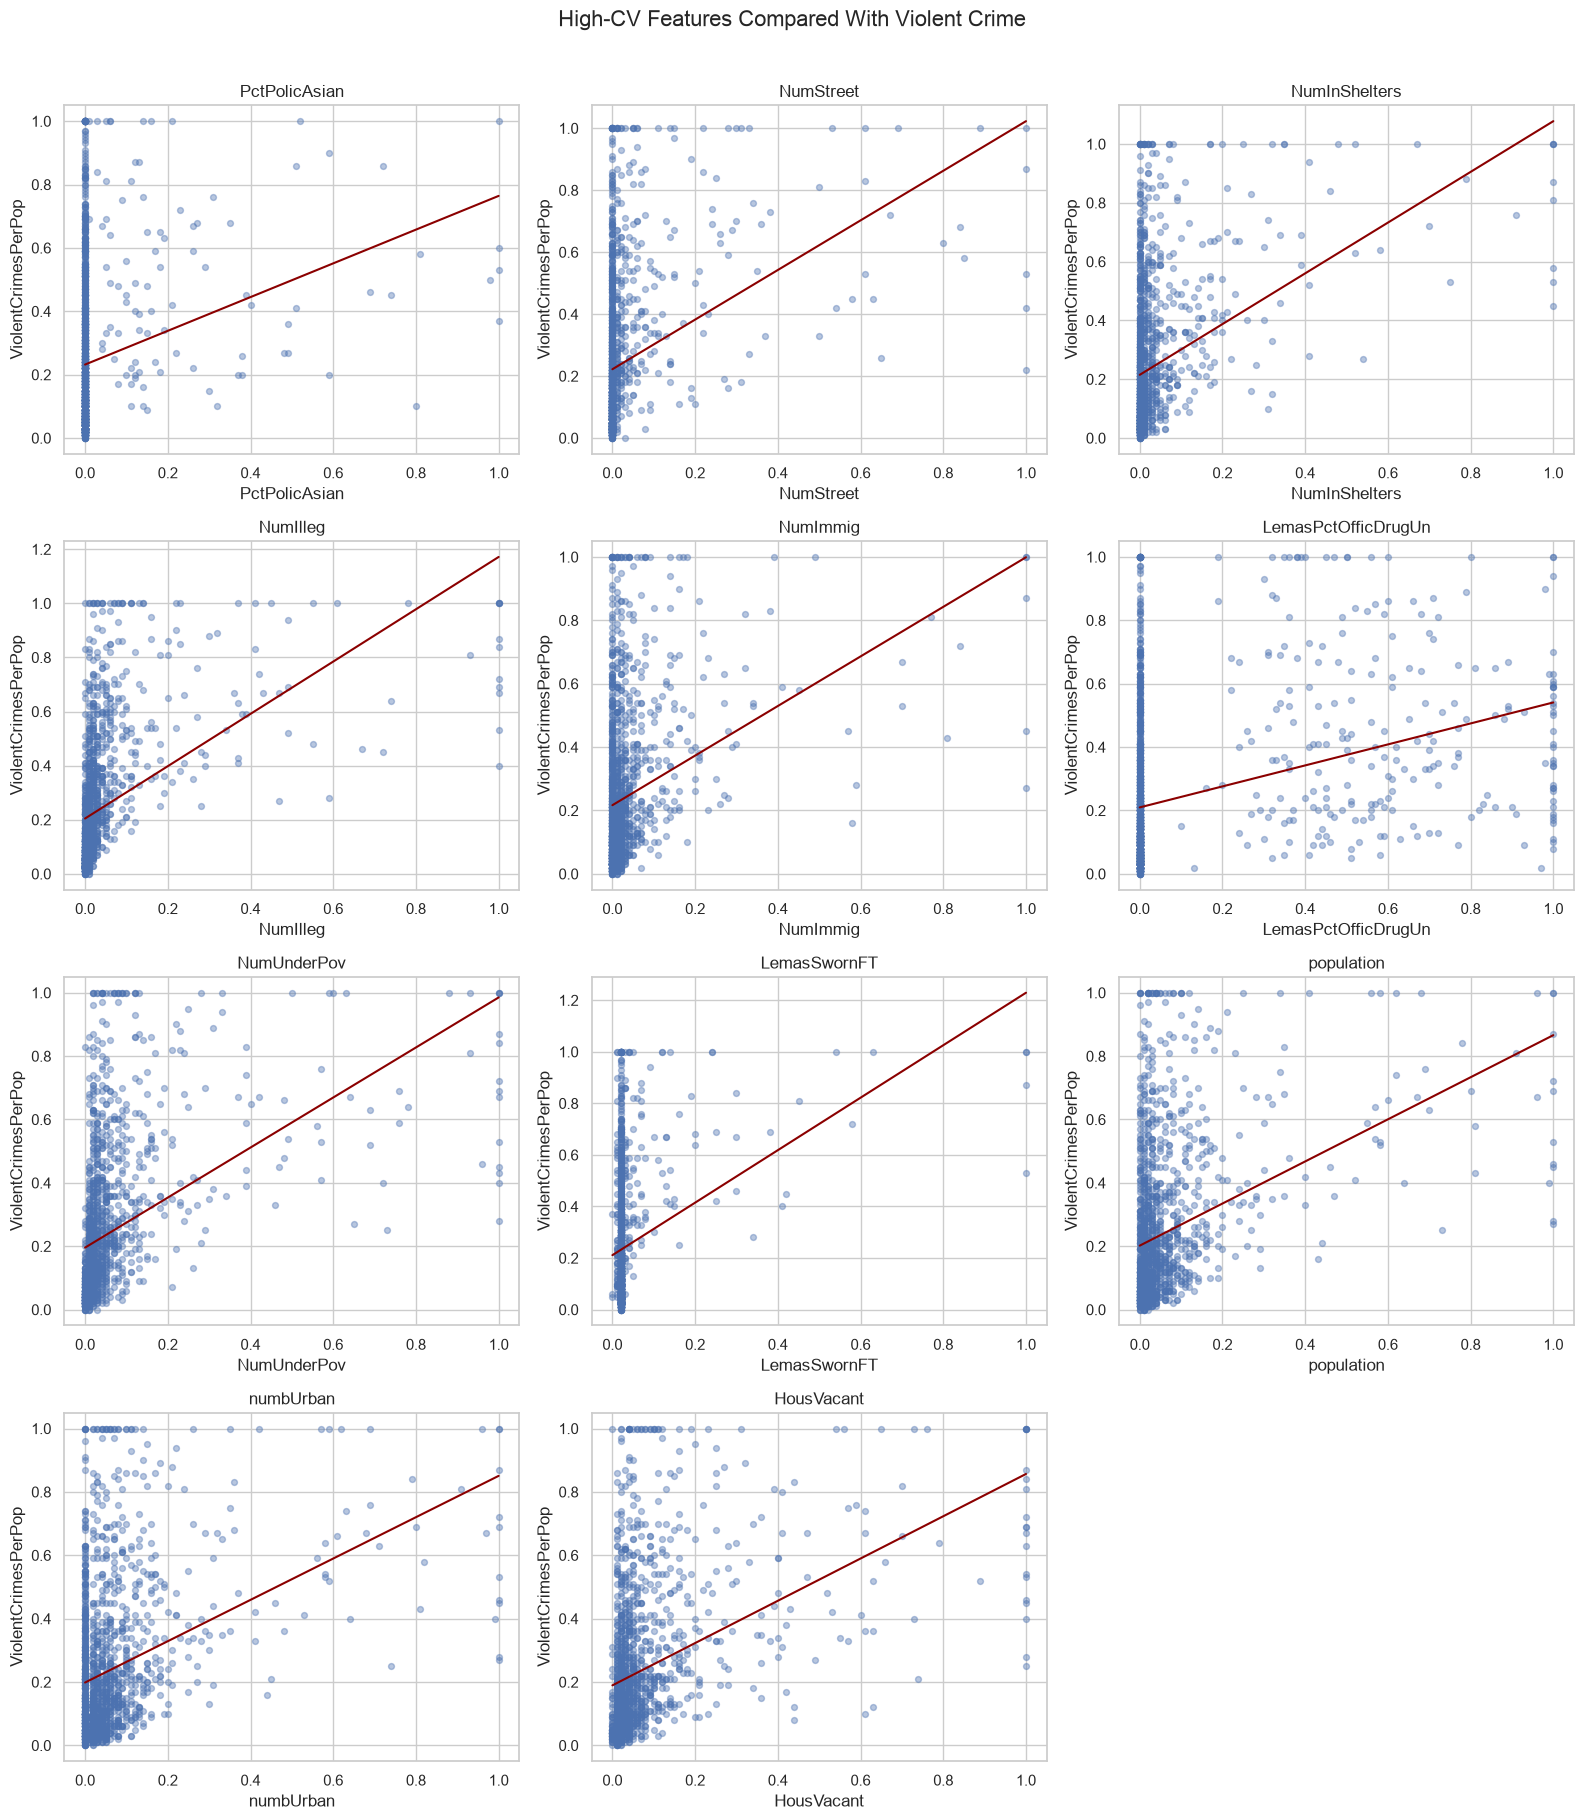

In [34]:
figure, plot_axes = plt.subplots(
    4,
    3,
    figsize=(16, 18)
)

flat_axes = plot_axes.flatten()

for graph_axis, field_name in zip(
    flat_axes,
    high_cv_fields
):
    sns.regplot(
        x=crime_train_filled[field_name],
        y=crime_train_y,
        ax=graph_axis,
        scatter_kws={
            "alpha": 0.4,
            "s": 18
        },
        line_kws={
            "color": "darkred",
            "linewidth": 1.5
        },
        ci=None
    )

    graph_axis.set_title(field_name)
    graph_axis.set_xlabel(field_name)
    graph_axis.set_ylabel("ViolentCrimesPerPop")

for unused_axis in flat_axes[
    len(high_cv_fields):
]:
    unused_axis.set_visible(False)

figure.suptitle(
    "High-CV Features Compared With Violent Crime",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

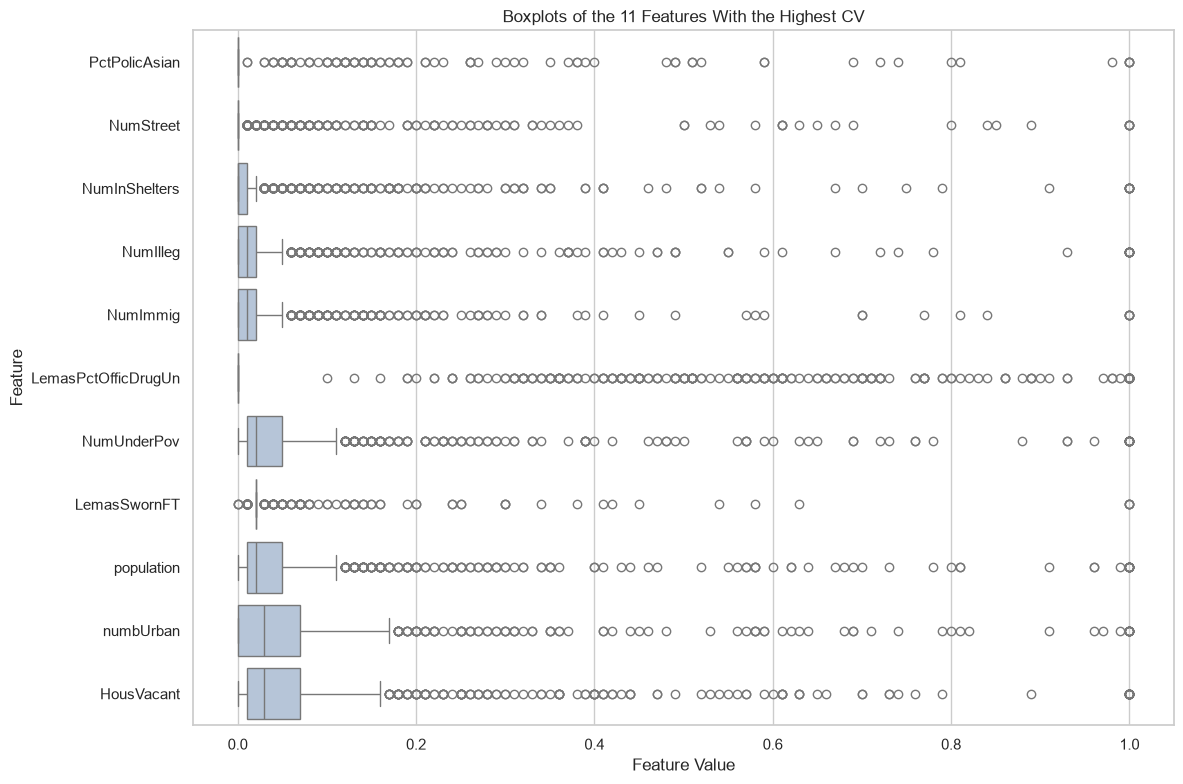

In [35]:
boxplot_frame = (
    crime_train_filled[high_cv_fields]
    .melt(
        var_name="feature",
        value_name="recorded_value"
    )
)

plt.figure(figsize=(12, 8))

sns.boxplot(
    data=boxplot_frame,
    x="recorded_value",
    y="feature",
    color="lightsteelblue"
)

plt.xlabel("Feature Value")
plt.ylabel("Feature")
plt.title(
    "Boxplots of the 11 Features With the Highest CV"
)

plt.tight_layout()
plt.show()

The boxplots show that many of the selected features are concentrated near
zero and have several larger values. This helps explain why their
coefficients of variation are high. Their means are relatively small, while
their values still vary across communities.

The scatterplots can show whether a feature appears to have a positive,
negative, or weak relationship with violent crime. However, the plots alone
cannot establish whether a feature is statistically significant. A formal
model and statistical test would be needed for that conclusion. The strong
correlations between some predictors would also need to be considered.

### 2(f) Ordinary Least Squares Regression

An ordinary least squares regression model was fitted using all 122
predictors. The model was trained on the first 1,495 observations and
evaluated on the test set. Mean squared error was used as the test error.

In [36]:

least_squares_fit = LinearRegression()

least_squares_fit.fit(
    crime_train_filled,
    crime_train_y
)

ols_train_guesses = least_squares_fit.predict(
    crime_train_filled
)

ols_test_guesses = least_squares_fit.predict(
    crime_test_filled
)

ols_training_error = mean_squared_error(
    crime_train_y,
    ols_train_guesses
)

ols_test_error = mean_squared_error(
    crime_test_y,
    ols_test_guesses
)

print(
    f"Training MSE: {ols_training_error:.6f}"
)

print(
    f"Test MSE: {ols_test_error:.6f}"
)


Training MSE: 0.016292
Test MSE: 0.017966


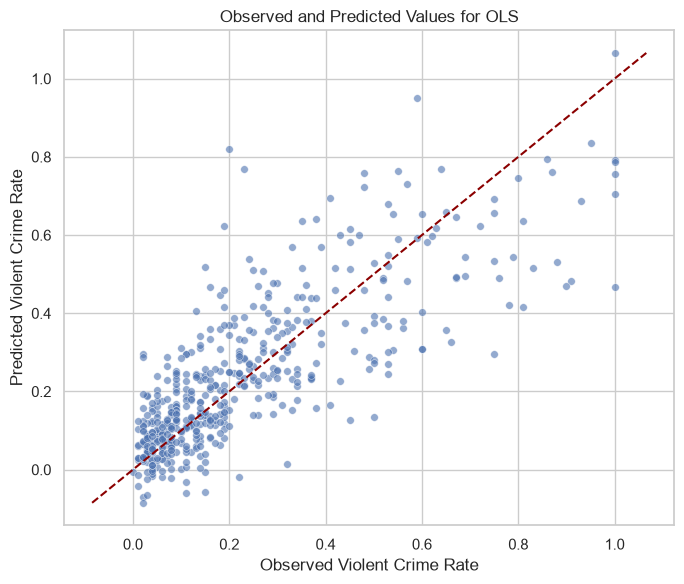

In [37]:
plt.figure(figsize=(7, 6))

sns.scatterplot(
    x=crime_test_y,
    y=ols_test_guesses,
    alpha=0.6,
    s=30
)

comparison_start = min(
    crime_test_y.min(),
    ols_test_guesses.min()
)

comparison_end = max(
    crime_test_y.max(),
    ols_test_guesses.max()
)

plt.plot(
    [comparison_start, comparison_end],
    [comparison_start, comparison_end],
    color="darkred",
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Observed Violent Crime Rate")
plt.ylabel("Predicted Violent Crime Rate")
plt.title(
    "Observed and Predicted Values for OLS"
)

plt.tight_layout()
plt.show()


The predicted values generally increase with the observed violent crime
rate. However, the points are more spread out for larger observed values.
This suggests that the model makes larger errors for some communities with
higher violent crime rates.

### 2(g) Ridge Regression

Ridge regression was fitted using all 122 predictors. Missing-value
imputation and standardization were included inside the pipeline. The value
of lambda was selected using five-fold cross-validation on the training set.
Mean squared error was used to compare the candidate values.

In [38]:
regression_folds = KFold(
    n_splits=5,
    shuffle=True,
    random_state=seed_value
)

ridge_steps = Pipeline([
    (
        "fill_missing",
        SimpleImputer(strategy="median")
    ),
    (
        "rescale",
        StandardScaler()
    ),
    (
        "ridge_model",
        Ridge()
    )
])

ridge_penalties = np.logspace(
    -4,
    4,
    100
)

ridge_search = GridSearchCV(
    estimator=ridge_steps,
    param_grid={
        "ridge_model__alpha": ridge_penalties
    },
    scoring="neg_mean_squared_error",
    cv=regression_folds,
    n_jobs=-1
)

ridge_search.fit(
    crime_train_x,
    crime_train_y
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...l', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'ridge_model__alpha': array([1.0000...00000000e+04])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defa

In [39]:
selected_ridge_penalty = (
    ridge_search.best_params_[
        "ridge_model__alpha"
    ]
)

ridge_cv_error = -ridge_search.best_score_

ridge_test_guesses = ridge_search.predict(
    crime_test_x
)

ridge_test_error = mean_squared_error(
    crime_test_y,
    ridge_test_guesses
)

print(
    f"Selected ridge lambda: "
    f"{selected_ridge_penalty:.6f}"
)

print(
    f"Best cross-validation MSE: "
    f"{ridge_cv_error:.6f}"
)

print(
    f"Ridge test MSE: "
    f"{ridge_test_error:.6f}"
)

Selected ridge lambda: 138.488637
Best cross-validation MSE: 0.019737
Ridge test MSE: 0.017360


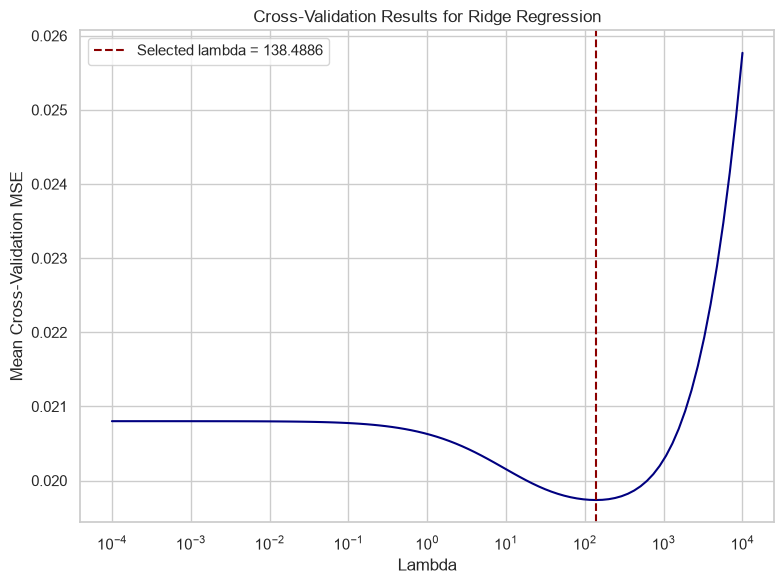

In [40]:
ridge_search_table = pd.DataFrame({
    "lambda": ridge_search.cv_results_[
        "param_ridge_model__alpha"
    ].astype(float),
    "mean_cv_mse": (
        -ridge_search.cv_results_[
            "mean_test_score"
        ]
    )
})

ridge_search_table = (
    ridge_search_table
    .sort_values("lambda")
)

plt.figure(figsize=(8, 6))

plt.semilogx(
    ridge_search_table["lambda"],
    ridge_search_table["mean_cv_mse"],
    color="navy"
)

plt.axvline(
    selected_ridge_penalty,
    color="darkred",
    linestyle="--",
    label=(
        f"Selected lambda = "
        f"{selected_ridge_penalty:.4f}"
    )
)

plt.xlabel("Lambda")
plt.ylabel("Mean Cross-Validation MSE")
plt.title("Cross-Validation Results for Ridge Regression")
plt.legend()
plt.tight_layout()
plt.show()

The OLS model had a training MSE of 0.016292 and a test MSE of 0.017966.

Cross-validation selected a ridge lambda of 138.488637. The ridge model had
a cross-validation MSE of 0.019737 and a test MSE of 0.017360. Its test error
was slightly lower than the OLS test error. This suggests that shrinking the
coefficients helped the model generalize a little better.

### 2(h) LASSO Regression

Two LASSO models were fitted. The first model used the predictors in their
original form. The second model standardized the predictors before fitting
LASSO. For both models, lambda was selected using five-fold
cross-validation.

LASSO can set some coefficients exactly equal to zero. Predictors with
nonzero coefficients are treated as selected variables.

In [41]:
lasso_penalties = np.logspace(
    -5,
    0,
    120
)

In [42]:
plain_lasso_steps = Pipeline([
    (
        "fill_missing",
        SimpleImputer(strategy="median")
    ),
    (
        "lasso_model",
        Lasso(
            max_iter=100000,
            tol=1e-6
        )
    )
])

plain_lasso_search = GridSearchCV(
    estimator=plain_lasso_steps,
    param_grid={
        "lasso_model__alpha": lasso_penalties
    },
    scoring="neg_mean_squared_error",
    cv=regression_folds,
    n_jobs=-1
)

plain_lasso_search.fit(
    crime_train_x,
    crime_train_y
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... tol=1e-06))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'lasso_model__alpha': array([1.0000...00000000e+00])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defaul

In [43]:
plain_lasso_penalty = (
    plain_lasso_search.best_params_[
        "lasso_model__alpha"
    ]
)

plain_lasso_cv_error = (
    -plain_lasso_search.best_score_
)

plain_lasso_guesses = (
    plain_lasso_search.predict(
        crime_test_x
    )
)

plain_lasso_test_error = mean_squared_error(
    crime_test_y,
    plain_lasso_guesses
)

plain_lasso_coefficients = pd.Series(
    plain_lasso_search
    .best_estimator_
    .named_steps["lasso_model"]
    .coef_,
    index=usable_fields
)

plain_selected_fields = (
    plain_lasso_coefficients[
        plain_lasso_coefficients.abs() > 1e-8
    ]
    .sort_values(
        key=np.abs,
        ascending=False
    )
)

print(
    f"Selected lambda without standardization: "
    f"{plain_lasso_penalty:.6f}"
)

print(
    f"Cross-validation MSE: "
    f"{plain_lasso_cv_error:.6f}"
)

print(
    f"Test MSE: "
    f"{plain_lasso_test_error:.6f}"
)

print(
    "Number of selected variables:",
    len(plain_selected_fields)
)

Selected lambda without standardization: 0.000112
Cross-validation MSE: 0.019515
Test MSE: 0.017641
Number of selected variables: 73


In [44]:
plain_selection_table = (
    plain_selected_fields
    .rename("coefficient")
    .reset_index()
    .rename(
        columns={
            "index": "selected_feature"
        }
    )
)

plain_selection_table.round(6)

,selected_feature,coefficient
0,agePct12t29,-0.271250
1,racepctblack,0.268110
2,PctPersDenseHous,0.216656
3,PctKids2Par,-0.198546
4,MedRent,0.164009
...,...,...
68,PolicAveOTWorked,-0.010099
69,PctTeen2Par,-0.009870
70,PctImmigRec10,-0.004314
71,MedNumBR,0.003861


In [45]:
scaled_lasso_steps = Pipeline([
    (
        "fill_missing",
        SimpleImputer(strategy="median")
    ),
    (
        "rescale",
        StandardScaler()
    ),
    (
        "lasso_model",
        Lasso(
            max_iter=100000,
            tol=1e-6
        )
    )
])

scaled_lasso_search = GridSearchCV(
    estimator=scaled_lasso_steps,
    param_grid={
        "lasso_model__alpha": lasso_penalties
    },
    scoring="neg_mean_squared_error",
    cv=regression_folds,
    n_jobs=-1
)

scaled_lasso_search.fit(
    crime_train_x,
    crime_train_y
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... tol=1e-06))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'lasso_model__alpha': array([1.0000...00000000e+00])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defaul

In [46]:
scaled_lasso_penalty = (
    scaled_lasso_search.best_params_[
        "lasso_model__alpha"
    ]
)

scaled_lasso_cv_error = (
    -scaled_lasso_search.best_score_
)

scaled_lasso_guesses = (
    scaled_lasso_search.predict(
        crime_test_x
    )
)

scaled_lasso_test_error = mean_squared_error(
    crime_test_y,
    scaled_lasso_guesses
)

scaled_lasso_coefficients = pd.Series(
    scaled_lasso_search
    .best_estimator_
    .named_steps["lasso_model"]
    .coef_,
    index=usable_fields
)

scaled_selected_fields = (
    scaled_lasso_coefficients[
        scaled_lasso_coefficients.abs() > 1e-8
    ]
    .sort_values(
        key=np.abs,
        ascending=False
    )
)

print(
    f"Selected standardized lambda: "
    f"{scaled_lasso_penalty:.6f}"
)

print(
    f"Cross-validation MSE: "
    f"{scaled_lasso_cv_error:.6f}"
)

print(
    f"Test MSE: "
    f"{scaled_lasso_test_error:.6f}"
)

print(
    "Number of selected variables:",
    len(scaled_selected_fields)
)

Selected standardized lambda: 0.000641
Cross-validation MSE: 0.019661
Test MSE: 0.017719
Number of selected variables: 76


In [47]:
scaled_selection_table = (
    scaled_selected_fields
    .rename("coefficient")
    .reset_index()
    .rename(
        columns={
            "index": "selected_feature"
        }
    )
)

scaled_selection_table.round(6)

,selected_feature,coefficient
0,racepctblack,0.067967
1,PctPersDenseHous,0.043121
2,agePct12t29,-0.042909
3,PctKids2Par,-0.040712
4,RentLowQ,-0.030639
...,...,...
71,PctOccupManu,0.000735
72,MedNumBR,0.000674
73,PctImmigRec10,-0.000640
74,PersPerOwnOccHous,-0.000185


In [48]:
lasso_summary = pd.DataFrame({
    "model": [
        "LASSO without standardization",
        "LASSO with standardization"
    ],
    "selected_lambda": [
        plain_lasso_penalty,
        scaled_lasso_penalty
    ],
    "cv_mse": [
        plain_lasso_cv_error,
        scaled_lasso_cv_error
    ],
    "test_mse": [
        plain_lasso_test_error,
        scaled_lasso_test_error
    ],
    "selected_variables": [
        len(plain_selected_fields),
        len(scaled_selected_fields)
    ]
})

lasso_summary.round(6)

,model,selected_lambda,cv_mse,test_mse,selected_variables
0,LASSO without standardization,0.000112,0.019515,0.017641,73
1,LASSO with standardization,0.000641,0.019661,0.017719,76


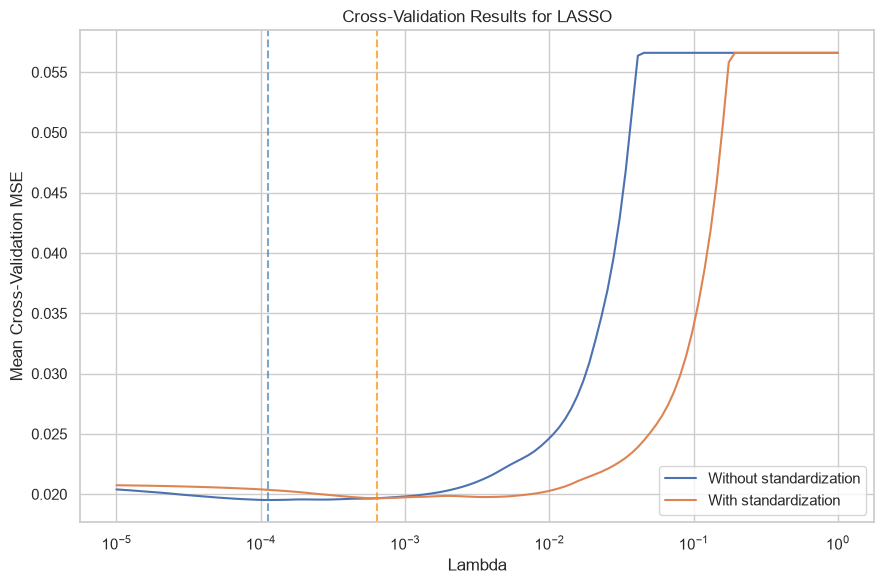

In [49]:
plain_lasso_curve = pd.DataFrame({
    "lambda": (
        plain_lasso_search.cv_results_[
            "param_lasso_model__alpha"
        ].astype(float)
    ),
    "mean_cv_mse": (
        -plain_lasso_search.cv_results_[
            "mean_test_score"
        ]
    )
}).sort_values("lambda")

scaled_lasso_curve = pd.DataFrame({
    "lambda": (
        scaled_lasso_search.cv_results_[
            "param_lasso_model__alpha"
        ].astype(float)
    ),
    "mean_cv_mse": (
        -scaled_lasso_search.cv_results_[
            "mean_test_score"
        ]
    )
}).sort_values("lambda")

plt.figure(figsize=(9, 6))

plt.semilogx(
    plain_lasso_curve["lambda"],
    plain_lasso_curve["mean_cv_mse"],
    label="Without standardization"
)

plt.semilogx(
    scaled_lasso_curve["lambda"],
    scaled_lasso_curve["mean_cv_mse"],
    label="With standardization"
)

plt.axvline(
    plain_lasso_penalty,
    color="steelblue",
    linestyle="--",
    alpha=0.7
)

plt.axvline(
    scaled_lasso_penalty,
    color="darkorange",
    linestyle="--",
    alpha=0.7
)

plt.xlabel("Lambda")
plt.ylabel("Mean Cross-Validation MSE")
plt.title("Cross-Validation Results for LASSO")
plt.legend()
plt.tight_layout()
plt.show()

In [50]:
print("LASSO WITHOUT STANDARDIZATION")
print(
    f"Selected lambda: "
    f"{plain_lasso_penalty:.6f}"
)
print(
    f"Cross-validation MSE: "
    f"{plain_lasso_cv_error:.6f}"
)
print(
    f"Test MSE: "
    f"{plain_lasso_test_error:.6f}"
)
print(
    f"Number of selected variables: "
    f"{len(plain_selected_fields)}"
)

print("\nSelected variables:")
for field_name in plain_selected_fields.index:
    print(field_name)


print("\n" + "=" * 50)
print("LASSO WITH STANDARDIZATION")
print(
    f"Selected lambda: "
    f"{scaled_lasso_penalty:.6f}"
)
print(
    f"Cross-validation MSE: "
    f"{scaled_lasso_cv_error:.6f}"
)
print(
    f"Test MSE: "
    f"{scaled_lasso_test_error:.6f}"
)
print(
    f"Number of selected variables: "
    f"{len(scaled_selected_fields)}"
)

print("\nSelected variables:")
for field_name in scaled_selected_fields.index:
    print(field_name)


print("\nMODEL COMPARISON")
display(
    lasso_summary.round(6)
)

LASSO WITHOUT STANDARDIZATION
Selected lambda: 0.000112
Cross-validation MSE: 0.019515
Test MSE: 0.017641
Number of selected variables: 73

Selected variables:
agePct12t29
racepctblack
PctPersDenseHous
PctKids2Par
MedRent
RentLowQ
NumStreet
PctEmploy
PctPopUnderPov
MalePctNevMarr
PctWorkMom
HousVacant
MalePctDivorce
pctWRetire
pctWInvInc
PctIlleg
NumImmig
PolicReqPerOffic
NumIlleg
MedRentPctHousInc
pctWWage
FemalePctDiv
MedOwnCostPctIncNoMtg
PctNotSpeakEnglWell
PctVacantBoarded
LemasSwFTFieldPerPop
PctLargHouseOccup
agePct12t21
NumInShelters
PctHousOccup
PctVacMore6Mos
PctHousLess3BR
PctPersOwnOccup
whitePerCap
pctWSocSec
PctForeignBorn
PersPerOccupHous
PctUsePubTrans
pctUrban
pctWPubAsst
PctRecImmig10
PctYoungKids2Par
LemasGangUnitDeploy
NumKindsDrugsSeiz
LandArea
indianPerCap
AsianPerCap
pctWFarmSelf
PctHousNoPhone
PctWOFullPlumb
PctSameCity85
HispPerCap
OtherPerCap
PctPolicAsian
blackPerCap
PolicCars
RacialMatchCommPol
PctLess9thGrade
PctPolicHisp
PctEmplManu
racePctAsian
PctPolicBl

,model,selected_lambda,cv_mse,test_mse,selected_variables
0,LASSO without standardization,0.000112,0.019515,0.017641,73
1,LASSO with standardization,0.000641,0.019661,0.017719,76


The LASSO model without standardization selected a lambda of 0.000112. It
kept 73 predictors and had a test MSE of 0.017641.

After standardization, cross-validation selected a lambda of 0.000641. This
model kept 76 predictors and had a test MSE of 0.017719.

The two test errors are very close. The model without standardization had a
slightly lower test error and used three fewer predictors, so it performed
a little better in this comparison. Both LASSO models had lower test errors
than OLS, but ridge regression still had the lowest test error so far.
Standardization also changed which variables were selected because LASSO's
penalty depends on the scale of the predictors.

### 2(i) Principal Component Regression

Principal component regression first replaces the original predictors with
principal components. A linear regression model is then fitted using those
components.

The predictors were standardized before PCA. The number of components was
selected using five-fold cross-validation on the training set.

In [51]:
pcr_steps = Pipeline([
    (
        "fill_missing",
        SimpleImputer(strategy="median")
    ),
    (
        "rescale",
        StandardScaler()
    ),
    (
        "pca_step",
        PCA(svd_solver="full")
    ),
    (
        "linear_fit",
        LinearRegression()
    )
])

component_choices = np.arange(
    1,
    len(usable_fields) + 1
)

pcr_search = GridSearchCV(
    estimator=pcr_steps,
    param_grid={
        "pca_step__n_components": component_choices
    },
    scoring="neg_mean_squared_error",
    cv=regression_folds,
    n_jobs=-1
)

pcr_search.fit(
    crime_train_x,
    crime_train_y
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'pca_step__n_components': array([ 1, ...20, 121, 122])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, de

In [52]:
chosen_component_count = (
    pcr_search.best_params_[
        "pca_step__n_components"
    ]
)

pcr_cv_error = -pcr_search.best_score_

pcr_test_guesses = pcr_search.predict(
    crime_test_x
)

pcr_test_error = mean_squared_error(
    crime_test_y,
    pcr_test_guesses
)

print(
    "Selected number of components:",
    chosen_component_count
)

print(
    f"Best cross-validation MSE: "
    f"{pcr_cv_error:.6f}"
)

print(
    f"PCR test MSE: "
    f"{pcr_test_error:.6f}"
)

Selected number of components: 60
Best cross-validation MSE: 0.020210
PCR test MSE: 0.018350


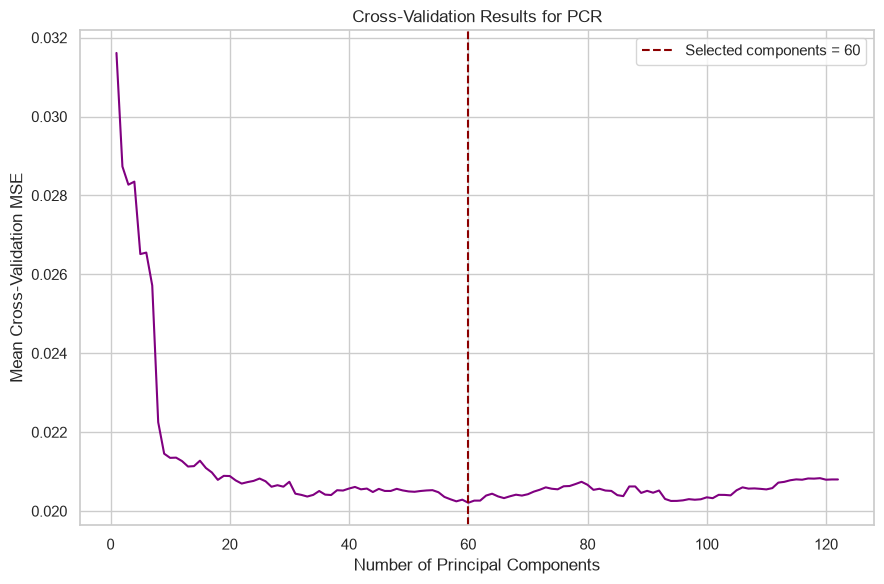

In [53]:
pcr_search_table = pd.DataFrame({
    "components": (
        pcr_search.cv_results_[
            "param_pca_step__n_components"
        ].astype(int)
    ),
    "mean_cv_mse": (
        -pcr_search.cv_results_[
            "mean_test_score"
        ]
    )
})

pcr_search_table = (
    pcr_search_table
    .sort_values("components")
)

plt.figure(figsize=(9, 6))

plt.plot(
    pcr_search_table["components"],
    pcr_search_table["mean_cv_mse"],
    color="purple",
    linewidth=1.5
)

plt.axvline(
    chosen_component_count,
    color="darkred",
    linestyle="--",
    label=(
        f"Selected components = "
        f"{chosen_component_count}"
    )
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Mean Cross-Validation MSE")
plt.title("Cross-Validation Results for PCR")
plt.legend()
plt.tight_layout()
plt.show()

In [54]:
selected_pca = (
    pcr_search
    .best_estimator_
    .named_steps["pca_step"]
)

variance_preserved = (
    selected_pca
    .explained_variance_ratio_
    .sum()
)

print(
    f"Variance explained by selected components: "
    f"{variance_preserved:.4f}"
)

Variance explained by selected components: 0.9806


Cross-validation selected 60 principal components. These components explained
98.06% of the variation in the predictors.

The PCR model had a cross-validation MSE of 0.020220 and a test MSE of
0.018350.Its test error was higher than the errors from OLS, ridge, and both
LASSO models. Although PCR reduced the predictors to 60 components, this did
not improve prediction on the test set.

### 2(j) XGBoost Regression

An XGBoost regression model was fitted to the training data. The L1
regularization parameter, alpha, was selected using five-fold
cross-validation. Mean squared error was used to compare the candidate
values.

In [55]:
from xgboost import XGBRegressor

In [56]:
boosting_steps = Pipeline([
    (
        "fill_missing",
        SimpleImputer(strategy="median")
    ),
    (
        "boosted_model",
        XGBRegressor(
            objective="reg:squarederror",
            n_estimators=500,
            learning_rate=0.03,
            max_depth=3,
            min_child_weight=1,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            random_state=seed_value,
            tree_method="hist",
            n_jobs=1
        )
    )
])

alpha_choices = np.concatenate([
    [0.0],
    np.logspace(-4, 2, 13)
])

alpha_choices

array([0.00000000e+00, 1.00000000e-04, 3.16227766e-04, 1.00000000e-03,
       3.16227766e-03, 1.00000000e-02, 3.16227766e-02, 1.00000000e-01,
       3.16227766e-01, 1.00000000e+00, 3.16227766e+00, 1.00000000e+01,
       3.16227766e+01, 1.00000000e+02])

In [57]:
boosting_search = GridSearchCV(
    estimator=boosting_steps,
    param_grid={
        "boosted_model__reg_alpha": alpha_choices
    },
    scoring="neg_mean_squared_error",
    cv=regression_folds,
    n_jobs=-1
)

boosting_search.fit(
    crime_train_x,
    crime_train_y
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'boosted_model__reg_alpha': array([0.0000...00000000e+02])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int

In [58]:
selected_boosting_alpha = (
    boosting_search.best_params_[
        "boosted_model__reg_alpha"
    ]
)

boosting_cv_error = (
    -boosting_search.best_score_
)

boosting_test_guesses = (
    boosting_search.predict(
        crime_test_x
    )
)

boosting_test_error = mean_squared_error(
    crime_test_y,
    boosting_test_guesses
)

print(
    f"Selected XGBoost alpha: "
    f"{selected_boosting_alpha:.6f}"
)

print(
    f"Best cross-validation MSE: "
    f"{boosting_cv_error:.6f}"
)

print(
    f"XGBoost test MSE: "
    f"{boosting_test_error:.6f}"
)

Selected XGBoost alpha: 0.003162
Best cross-validation MSE: 0.019558
XGBoost test MSE: 0.015761


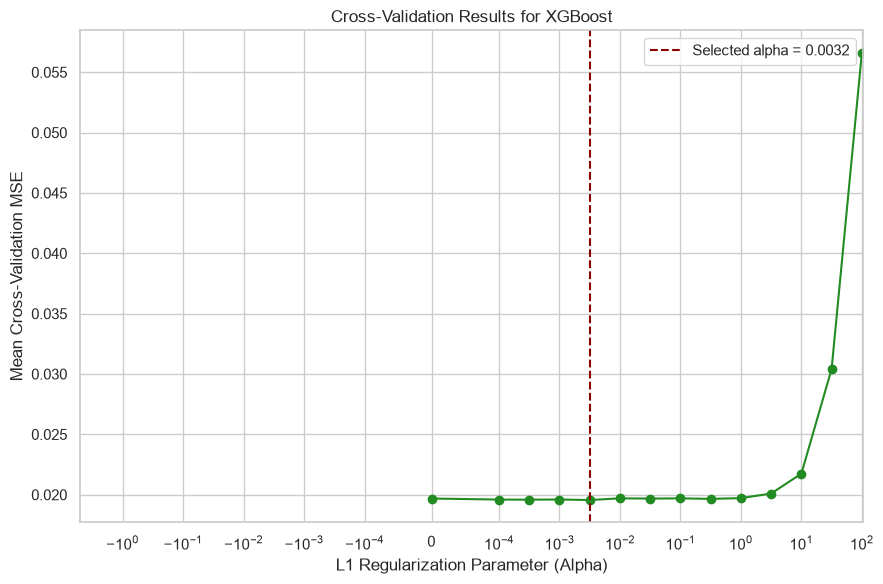

In [59]:
boosting_search_table = pd.DataFrame({
    "alpha": (
        boosting_search.cv_results_[
            "param_boosted_model__reg_alpha"
        ].astype(float)
    ),
    "mean_cv_mse": (
        -boosting_search.cv_results_[
            "mean_test_score"
        ]
    )
})

boosting_search_table = (
    boosting_search_table
    .sort_values("alpha")
)

plt.figure(figsize=(9, 6))

plt.plot(
    boosting_search_table["alpha"],
    boosting_search_table["mean_cv_mse"],
    marker="o",
    color="forestgreen"
)

plt.axvline(
    selected_boosting_alpha,
    color="darkred",
    linestyle="--",
    label=(
        f"Selected alpha = "
        f"{selected_boosting_alpha:.4f}"
    )
)

plt.xscale(
    "symlog",
    linthresh=0.0001
)

plt.xlabel("L1 Regularization Parameter (Alpha)")
plt.ylabel("Mean Cross-Validation MSE")
plt.title("Cross-Validation Results for XGBoost")
plt.legend()
plt.tight_layout()
plt.show()

Cross-validation selected an alpha of 0.003162 for XGBoost. The model had a
cross-validation MSE of 0.019558 and a test MSE of 0.015761.

This was the lowest test error among all the models. The result suggests that
XGBoost captured relationships that the linear regression models and PCR
could not capture.

### Comparison of the Regression Models

The table below compares the test errors from all the regression models.
A smaller mean squared error indicates better test performance.

In [60]:
final_model_comparison = pd.DataFrame({
    "model": [
        "Ordinary least squares",
        "Ridge regression",
        "LASSO without standardization",
        "LASSO with standardization",
        "Principal component regression",
        "XGBoost"
    ],
    "selected_setting": [
        "None",
        f"lambda = {selected_ridge_penalty:.6f}",
        f"lambda = {plain_lasso_penalty:.6f}",
        f"lambda = {scaled_lasso_penalty:.6f}",
        f"components = {chosen_component_count}",
        f"alpha = {selected_boosting_alpha:.6f}"
    ],
    "cross_validation_mse": [
        np.nan,
        ridge_cv_error,
        plain_lasso_cv_error,
        scaled_lasso_cv_error,
        pcr_cv_error,
        boosting_cv_error
    ],
    "test_mse": [
        ols_test_error,
        ridge_test_error,
        plain_lasso_test_error,
        scaled_lasso_test_error,
        pcr_test_error,
        boosting_test_error
    ]
})

final_model_comparison = (
    final_model_comparison
    .sort_values(
        by="test_mse"
    )
    .reset_index(drop=True)
)

final_model_comparison.round(6)

,model,selected_setting,cross_validation_mse,test_mse
0,XGBoost,alpha = 0.003162,0.019558,0.015761
1,Ridge regression,lambda = 138.488637,0.019737,0.017360
2,LASSO without standardization,lambda = 0.000112,0.019515,0.017641
3,LASSO with standardization,lambda = 0.000641,0.019661,0.017719
4,Ordinary least squares,None,NaN,0.017966
5,Principal component regression,components = 60,0.020210,0.018350


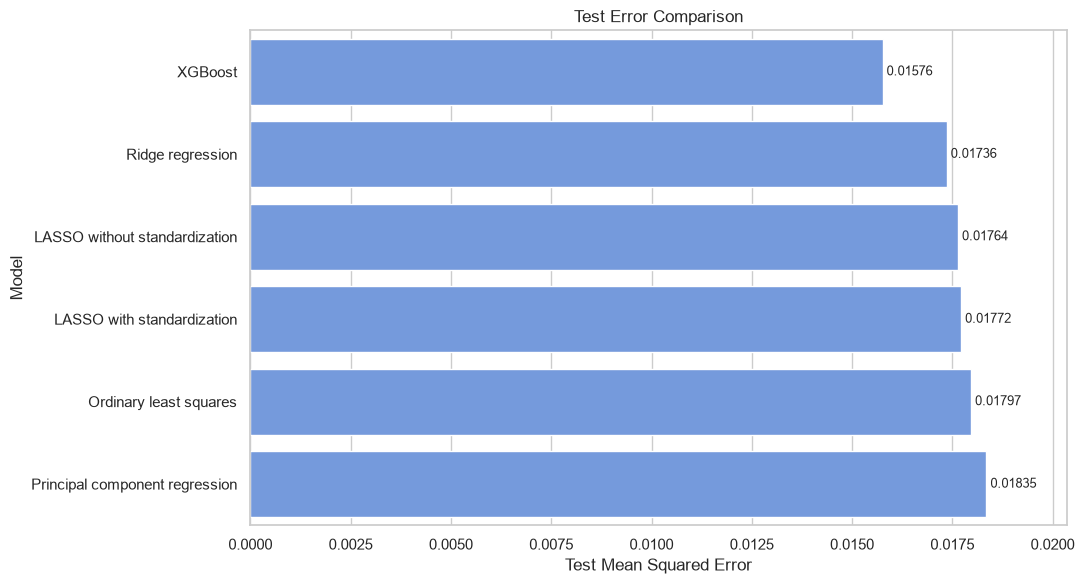

In [61]:
plt.figure(figsize=(11, 6))

comparison_plot = sns.barplot(
    data=final_model_comparison,
    x="test_mse",
    y="model",
    color="cornflowerblue"
)

for bar_patch in comparison_plot.patches:
    error_value = bar_patch.get_width()

    comparison_plot.text(
        error_value + 0.0001,
        bar_patch.get_y() + bar_patch.get_height() / 2,
        f"{error_value:.5f}",
        va="center",
        fontsize=9
    )

plt.xlabel("Test Mean Squared Error")
plt.ylabel("Model")
plt.title("Test Error Comparison")
plt.xlim(
    0,
    final_model_comparison["test_mse"].max() + 0.002
)

plt.tight_layout()
plt.show()

### Final Comparison

XGBoost had the lowest test MSE at 0.015761, so it gave the best prediction
performance on the test set. Its error was about 9.2% lower than the ridge
test error and about 12.3% lower than the OLS test error.

Ridge regression was the best linear model, with a test MSE of 0.017360.
Both LASSO models performed slightly better than OLS, but standardizing the
features did not improve the LASSO test result in this case. PCR had the
highest test error even though its 60 selected components explained 98.06%
of the predictor variation.

Based on the test errors, XGBoost was the best model for this dataset.